In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

**Importation de toutes les bibliothèques**

In [2]:

# ==========================================
# 1. GENERAL LIBRARIES
# ==========================================
import os
import re
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# ==========================================
# 2. DATASET
# ==========================================
from datasets import load_dataset, Dataset, DatasetDict
from huggingface_hub import login

# ==========================================
# 3. MACHINE LEARNING
# ==========================================
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_class_weight

# ==========================================
# 4. EVALUATION
# ==========================================
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ==========================================
# 5. WORD EMBEDDINGS
# ==========================================
from gensim.models import Word2Vec, FastText

# ==========================================
# 6. DEEP LEARNING
# ==========================================
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# ==========================================
# 7. TRANSFORMERS
# ==========================================
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding
)

# ==========================================
# 8. REPRODUCIBILITY
# ==========================================
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("All libraries imported successfully!")
print("Device:", device)


All libraries imported successfully!
Device: cuda


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import torch
import transformers
import datasets
import gensim

print("All essential libraries are working!")
print("GPU available:", torch.cuda.is_available())


All essential libraries are working!
GPU available: True


# ****chargement de base de données****

In [4]:

from huggingface_hub import login
from datasets import load_dataset
from getpass import getpass

# Authentification Hugging Face
login(token=getpass("HF Token: "))

# Chargement du dataset Darija marocaine
dataset = load_dataset("afrihate/afrihate", "ary")

# Vérification
print(dataset)

for split in dataset:
    print(f"{split}: {len(dataset[split])} exemples")
    print("Colonnes:", dataset[split].column_names)

# Aperçu des données
df = dataset["train"].to_pandas()
display(df.head())


HF Token:  ········


DatasetDict({
    train: Dataset({
        features: ['id', 'tweet', 'label'],
        num_rows: 3240
    })
    validation: Dataset({
        features: ['id', 'tweet', 'label'],
        num_rows: 695
    })
    test: Dataset({
        features: ['id', 'tweet', 'label'],
        num_rows: 699
    })
})
train: 3240 exemples
Colonnes: ['id', 'tweet', 'label']
validation: 695 exemples
Colonnes: ['id', 'tweet', 'label']
test: 699 exemples
Colonnes: ['id', 'tweet', 'label']


,id,tweet,label
0,train_darija_00001,هاد بغل شبع سبان https://t.co/ty8tcox2cx,Abuse
1,train_darija_00002,السلام عليكم ورحمة الله وبركاته إخواني بدي من...,Normal
2,train_darija_00003,@nasronasro1988 @LesVerts اسجد قود في دارك يا بغل,Abuse
3,train_darija_00004,@nivalove3 @___Marocaine___ @SihamLabdaoui @Li...,Abuse
4,train_darija_00005,كيقرا معاية واحد خونا مكيسكتش كيفرع ليا كري با...,Abuse


# partie 1 — Exploratory Data Analysis (EDA)

***Dataset Overview***

In [5]:

# Identification des splits et des colonnes
for split in dataset:
    print(f"\n{split}: {len(dataset[split])} tweets")
    print("Colonnes:", dataset[split].column_names)

# Aperçu du train
df_train = dataset["train"].to_pandas()

print("\nShape:", df_train.shape)
display(df_train.head())
print("\nValeurs manquantes:")
print(df_train.isnull().sum())
print("\nDoublons exacts:", df_train.duplicated().sum())



train: 3240 tweets
Colonnes: ['id', 'tweet', 'label']

validation: 695 tweets
Colonnes: ['id', 'tweet', 'label']

test: 699 tweets
Colonnes: ['id', 'tweet', 'label']

Shape: (3240, 3)


,id,tweet,label
0,train_darija_00001,هاد بغل شبع سبان https://t.co/ty8tcox2cx,Abuse
1,train_darija_00002,السلام عليكم ورحمة الله وبركاته إخواني بدي من...,Normal
2,train_darija_00003,@nasronasro1988 @LesVerts اسجد قود في دارك يا بغل,Abuse
3,train_darija_00004,@nivalove3 @___Marocaine___ @SihamLabdaoui @Li...,Abuse
4,train_darija_00005,كيقرا معاية واحد خونا مكيسكتش كيفرع ليا كري با...,Abuse



Valeurs manquantes:
id       0
tweet    0
label    0
dtype: int64

Doublons exacts: 0


***Class Distribution***

,Count,Percentage (%)
label,,
Abuse,1588,49.01
Normal,1182,36.48
Hate,470,14.51


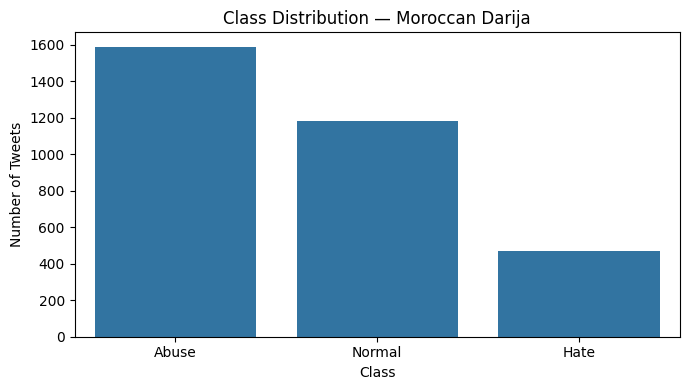

In [6]:

# Détection de la colonne des labels
label_col = next(
    (c for c in ["label", "labels", "class", "category"]
     if c in df_train.columns),
    None
)

if label_col is None:
    print("Colonnes disponibles:", df_train.columns.tolist())
else:
    counts = df_train[label_col].value_counts()
    percentages = df_train[label_col].value_counts(normalize=True) * 100

    display(pd.DataFrame({
        "Count": counts,
        "Percentage (%)": percentages.round(2)
    }))

    plt.figure(figsize=(7, 4))
    sns.countplot(data=df_train, x=label_col,
                  order=counts.index)
    plt.title("Class Distribution — Moroccan Darija")
    plt.xlabel("Class")
    plt.ylabel("Number of Tweets")
    plt.tight_layout()
    plt.show()


**EDA : Text Length Analysis**

TEXT LENGTH STATISTICS


,word_count,char_count
count,3240.000000,3240.000000
mean,18.416667,111.923765
std,11.968616,67.770193
min,1.000000,4.000000
25%,10.000000,59.000000
50%,16.000000,105.000000
75%,23.000000,137.000000
max,61.000000,339.000000



95th percentile (words): 46.0
95th percentile (characters): 268.0499999999997


,word_count,char_count
label,,
Abuse,14.29,89.65
Hate,19.89,119.76
Normal,23.38,138.73


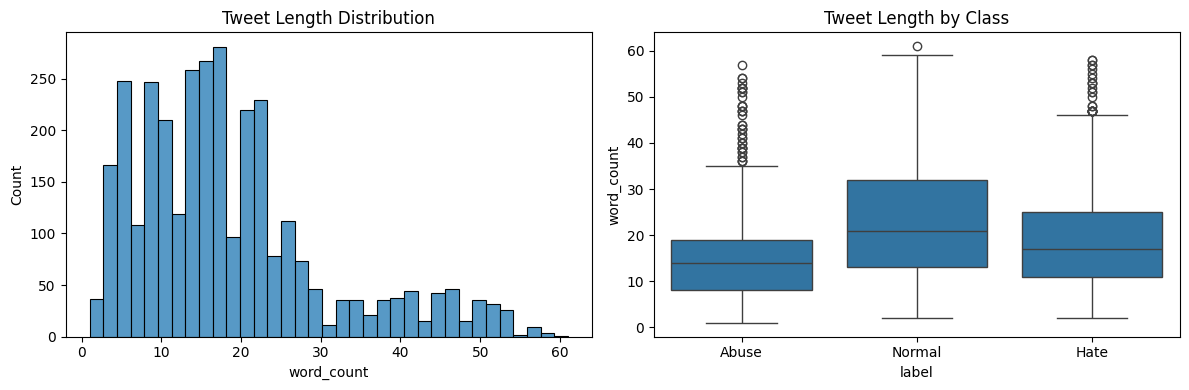

In [7]:

# ==========================================
# TEXT LENGTH ANALYSIS
# ==========================================

df_train["word_count"] = df_train["tweet"].str.split().str.len()
df_train["char_count"] = df_train["tweet"].str.len()

# Statistiques
print("TEXT LENGTH STATISTICS")
display(df_train[["word_count", "char_count"]].describe())

print("\n95th percentile (words):",
      df_train["word_count"].quantile(0.95))

print("95th percentile (characters):",
      df_train["char_count"].quantile(0.95))

# Distribution par classe
display(df_train.groupby("label")[["word_count", "char_count"]].mean().round(2))

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_train["word_count"], bins=35, ax=axes[0])
axes[0].set_title("Tweet Length Distribution")

sns.boxplot(data=df_train, x="label", y="word_count", ax=axes[1])
axes[1].set_title("Tweet Length by Class")

plt.tight_layout()
plt.show()


# Partie 2 : Text Preprocessing

**Text Cleaning & Normalization**

In [9]:


# Chargement des 3 splits en DataFrames

df_train = dataset["train"].to_pandas()
df_val = dataset["validation"].to_pandas()
df_test = dataset["test"].to_pandas()

print("Train:", df_train.shape)
print("Validation:", df_val.shape)
print("Test:", df_test.shape)


Train: (3240, 3)
Validation: (695, 3)
Test: (699, 3)


In [10]:

# ==========================================
# TEXT PREPROCESSING - MOROCCAN DARIJA
# ==========================================

import re
import pandas as pd

def clean_text(text):
    text = str(text)

    # URLs et mentions
    text = re.sub(r'https?://\S+|www\.\S+', ' URL ', text)
    text = re.sub(r'@\w+', ' USER ', text)

    # Suppression des diacritiques arabes
    text = re.sub(r'[\u064B-\u065F\u0670]', '', text)

    # Suppression du tatweel
    text = text.replace('ـ', '')

    # Normalisation arabe légère
    text = re.sub(r'[إأآٱ]', 'ا', text)
    text = text.replace('ى', 'ي')

    # Répétitions excessives (3+ vers 2)
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)

    # Espaces multiples
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Application sur les 3 splits
for df in [df_train, df_val, df_test]:
    df["clean_tweet"] = df["tweet"].apply(clean_text)

# Comparaison avant / après
display(
    df_train[["tweet", "clean_tweet", "label"]].head(10)
)


,tweet,clean_tweet,label
0,هاد بغل شبع سبان https://t.co/ty8tcox2cx,هاد بغل شبع سبان URL,Abuse
1,السلام عليكم ورحمة الله وبركاته إخواني بدي من...,السلام عليكم ورحمة الله وبركاته اخواني بدي منك...,Normal
2,@nasronasro1988 @LesVerts اسجد قود في دارك يا بغل,USER USER اسجد قود في دارك يا بغل,Abuse
3,@nivalove3 @___Marocaine___ @SihamLabdaoui @Li...,USER USER USER USER USER حمارة ركزي فرنسا خرجت...,Abuse
4,كيقرا معاية واحد خونا مكيسكتش كيفرع ليا كري با...,كيقرا معاية واحد خونا مكيسكتش كيفرع ليا كري با...,Abuse
5,karimOUTTA J imagine hadik FZ ka interviewi ch...,karimOUTTA J imagine hadik FZ ka interviewi ch...,Abuse
6,سيرجي روبيرتو كان ملحد و قلبها ليهودي باش يتزو...,سيرجي روبيرتو كان ملحد و قلبها ليهودي باش يتزو...,Normal
7,#hananelkhaer شوفو تحلاب وشوفو علم مغرب كيف حط...,#hananelkhaer شوفو تحلاب وشوفو علم مغرب كيف حط...,Abuse
8,AZ__TEAM Abdalslaam_alz عبد السلام يستهل كل ال...,AZ__TEAM Abdalslaam_alz عبد السلام يستهل كل ال...,Normal
9,@3hAOXQMg3nIdgdU @basmaTAM661 @ali_king102 \nه...,USER USER USER هه شوية غايقول لك تنهنان انا مغ...,Abuse


**Preprocessing Statistics**

In [11]:

print("Train:", len(df_train))
print("Validation:", len(df_val))
print("Test:", len(df_test))

print("\nEmpty cleaned tweets:",
      (df_train["clean_tweet"] == "").sum())

print("Modified tweets:",
      (df_train["tweet"] != df_train["clean_tweet"]).sum())

print("Duplicate cleaned tweets:",
      df_train["clean_tweet"].duplicated().sum())


Train: 3240
Validation: 695
Test: 699

Empty cleaned tweets: 0
Modified tweets: 2600
Duplicate cleaned tweets: 62


# Partie 3 — TF-IDF + Machine Learning

**Baseline Models**


========== Logistic Regression ==========
              precision    recall  f1-score   support

       Abuse       0.88      0.90      0.89       340
        Hate       0.71      0.71      0.71       102
      Normal       0.82      0.80      0.81       253

    accuracy                           0.84       695
   macro avg       0.80      0.80      0.80       695
weighted avg       0.84      0.84      0.84       695


========== Linear SVM ==========
              precision    recall  f1-score   support

       Abuse       0.88      0.94      0.91       340
        Hate       0.77      0.60      0.67       102
      Normal       0.85      0.84      0.84       253

    accuracy                           0.85       695
   macro avg       0.83      0.79      0.81       695
weighted avg       0.85      0.85      0.85       695


MODEL COMPARISON — VALIDATION


,Model,Macro-F1,Hate F1,AP Abuse,AP Hate,AP Normal
0,Linear SVM,0.8079,0.6740,0.9567,0.7121,0.9199
1,Logistic Regression,0.8031,0.7059,0.9582,0.7676,0.9237


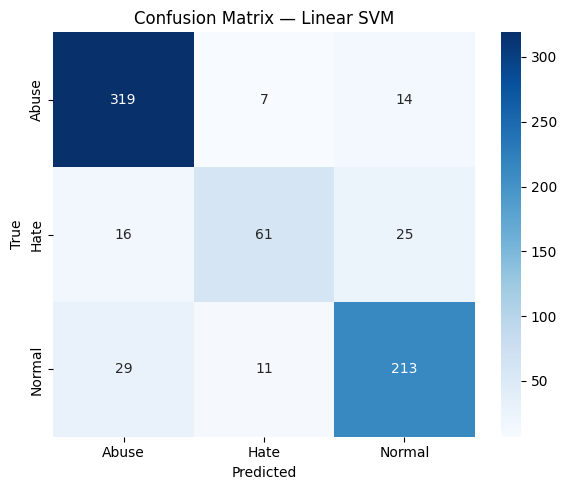

Best Model: Linear SVM
Best Macro-F1: 0.8079


In [17]:

# ========================================================
# PART A — TF-IDF + LOGISTIC REGRESSION VS LINEAR SVM
# ========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    f1_score, classification_report,
    average_precision_score, confusion_matrix
)

# 1. Data
X_train = df_train["clean_tweet"]
y_train = df_train["label"]
X_val = df_val["clean_tweet"]
y_val = df_val["label"]

CLASSES = ["Abuse", "Hate", "Normal"]

# 2. TF-IDF: Word (1-2) + Character (2-5)
def create_features():
    return FeatureUnion([
        ("word", TfidfVectorizer(
            analyzer="word",
            ngram_range=(1, 2),
            min_df=2,
            max_features=30000
        )),
        ("char", TfidfVectorizer(
            analyzer="char",
            ngram_range=(2, 5),
            min_df=2,
            max_features=50000
        ))
    ])

# 3. Models
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),
    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    )
}

results = []
trained_models_A = {}

# 4. Training and evaluation
for name, classifier in models.items():

    pipeline = Pipeline([
        ("tfidf", create_features()),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_val)

    # Continuous scores for Average Precision
    if hasattr(pipeline, "predict_proba"):
        scores = pipeline.predict_proba(X_val)
    else:
        scores = pipeline.decision_function(X_val)

    model_classes = list(pipeline.classes_)

    metrics = {
        "Model": name,
        "Macro-F1": f1_score(
            y_val, y_pred, average="macro"
        ),
        "Hate F1": f1_score(
            y_val, y_pred,
            labels=["Hate"],
            average="macro"
        )
    }

    for label in CLASSES:
        idx = model_classes.index(label)
        metrics[f"AP {label}"] = average_precision_score(
            (y_val == label).astype(int),
            scores[:, idx]
        )

    results.append(metrics)
    trained_models_A[name] = pipeline

    print(f"\n========== {name} ==========")
    print(classification_report(
        y_val, y_pred,
        labels=CLASSES,
        zero_division=0
    ))

# 5. Model comparison
comparison_A = pd.DataFrame(results).sort_values(
    "Macro-F1", ascending=False
).reset_index(drop=True)

print("\nMODEL COMPARISON — VALIDATION")
display(comparison_A.round(4))

# 6. Best model confusion matrix
best_name_A = comparison_A.iloc[0]["Model"]
best_model_A = trained_models_A[best_name_A]

cm = confusion_matrix(
    y_val,
    best_model_A.predict(X_val),
    labels=CLASSES
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)
plt.title(f"Confusion Matrix — {best_name_A}")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

print("Best Model:", best_name_A)
print("Best Macro-F1:",
      round(comparison_A.iloc[0]["Macro-F1"], 4))


**Script Variation + Lexicon Baseline**

In [20]:

# ================================================
# PART A — SCRIPT ANALYSIS + INSULT LEXICON
# ================================================

import re
import pandas as pd
from collections import Counter
from sklearn.metrics import f1_score, classification_report

# 1. Detect writing system
def detect_script(text):
    arabic = len(re.findall(r'[\u0600-\u06FF]', str(text)))
    latin = len(re.findall(r'[a-zA-Z]', str(text)))

    if arabic > 0 and latin > 0:
        return "Mixed"
    elif arabic > 0:
        return "Arabic"
    elif latin > 0:
        return "Latin"
    return "Other"

for df in [df_train, df_val, df_test]:
    df["script"] = df["tweet"].apply(detect_script)

# 2. Distribution by script
print("SCRIPT DISTRIBUTION — TRAIN")
print(df_train["script"].value_counts())

print("\nCLASS DISTRIBUTION BY SCRIPT (%)")
script_table = pd.crosstab(
    df_train["script"],
    df_train["label"],
    normalize="index"
) * 100

display(script_table.round(2))

# 3. Frequent tokens from Abuse training tweets
abuse_texts = df_train.loc[
    df_train["label"] == "Abuse", "clean_tweet"
]

tokens = []
for tweet in abuse_texts:
    tokens.extend(re.findall(r'\b\w+\b', tweet.lower()))

frequencies = Counter(tokens)

# Insult lexicon — updated
candidate_insults = [
    "بغل", "حمار", "كلب",
    "حمارة", "حيوان", "غبي", "مكلخ"
]

insult_lexicon = [
    w for w in candidate_insults
    if frequencies[w] > 0
]

print("\nINSULT LEXICON (TRAIN):")
print([(w, frequencies[w]) for w in insult_lexicon])

# 4. Rule-based baseline
def rule_predict(text):
    words = set(re.findall(r'\b\w+\b', str(text).lower()))

    if any(w in words for w in insult_lexicon):
        return "Abuse"

    return "Normal"

rule_preds = df_val["clean_tweet"].apply(rule_predict)

print("\nRULE-BASED BASELINE — VALIDATION")
print("Macro-F1:", round(
    f1_score(
        df_val["label"],
        rule_preds,
        labels=["Abuse", "Hate", "Normal"],
        average="macro",
        zero_division=0
    ), 4
))

print(classification_report(
    df_val["label"],
    rule_preds,
    labels=["Abuse", "Hate", "Normal"],
    zero_division=0
))

# 5. Class distribution by script (counts)
display(pd.crosstab(
    df_train["script"],
    df_train["label"]
))


SCRIPT DISTRIBUTION — TRAIN
script
Mixed     1941
Latin      959
Arabic     340
Name: count, dtype: int64

CLASS DISTRIBUTION BY SCRIPT (%)


label,Abuse,Hate,Normal
script,,,
Arabic,26.76,17.06,56.18
Latin,74.35,10.11,15.54
Mixed,40.39,16.23,43.38



INSULT LEXICON (TRAIN):
[('بغل', 48), ('حمار', 68), ('كلب', 12), ('حمارة', 144), ('حيوان', 4), ('غبي', 2), ('مكلخ', 44)]

RULE-BASED BASELINE — VALIDATION
Macro-F1: 0.265
              precision    recall  f1-score   support

       Abuse       0.88      0.14      0.23       340
        Hate       0.00      0.00      0.00       102
      Normal       0.39      0.99      0.56       253

    accuracy                           0.43       695
   macro avg       0.42      0.38      0.26       695
weighted avg       0.57      0.43      0.32       695



label,Abuse,Hate,Normal
script,,,
Arabic,91,58,191
Latin,713,97,149
Mixed,784,315,842


# Partie B — Zero-Shot NLI

**mDeBERTa-v3-base-mnli-xnli**

In [21]:

# ==========================================
# PART B1 — ZERO-SHOT NLI
# ==========================================

import numpy as np
import pandas as pd
import torch
from transformers import pipeline
from sklearn.metrics import (
    f1_score, classification_report,
    average_precision_score
)

MODEL_ID = "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
CLASSES = ["Abuse", "Hate", "Normal"]

# 1. Load pretrained model (no fine-tuning)
nli = pipeline(
    "zero-shot-classification",
    model=MODEL_ID,
    device=0 if torch.cuda.is_available() else -1
)

# 2. Three hypothesis formulations
hypotheses = {
    "Arabic": {
        "Abuse": "نص فيه سب وشتم لشخص",
        "Hate": "نص فيه كراهية ضد مجموعة من الناس",
        "Normal": "نص عادي ومحايد"
    },
    "French": {
        "Abuse": "une insulte envers une personne",
        "Hate": "un discours haineux envers un groupe",
        "Normal": "un contenu neutre"
    },
    "English": {
        "Abuse": "an insult directed at a person",
        "Hate": "hate speech targeting a group",
        "Normal": "neutral content"
    }
}

# 3. Validation data (original tweets)
texts = df_val["tweet"].astype(str).tolist()
y_true = df_val["label"].tolist()

results_B1 = []
predictions_B1 = {}

# 4. Evaluation for each language
for language, descriptions in hypotheses.items():

    print(f"\nEvaluating {language}...")

    labels = list(descriptions.values())

    outputs = nli(
        texts,
        candidate_labels=labels,
        hypothesis_template="Ce texte est {}.",
        multi_label=False,
        batch_size=16,
        truncation=True,
        max_length=128
    )

    if isinstance(outputs, dict):
        outputs = [outputs]

    scores = np.array([
        [dict(zip(out["labels"], out["scores"]))[label]
         for label in labels]
        for out in outputs
    ])

    y_pred = np.array(CLASSES)[scores.argmax(axis=1)]

    macro_f1 = f1_score(
        y_true, y_pred, average="macro"
    )

    hate_f1 = f1_score(
        y_true, y_pred,
        labels=["Hate"],
        average="macro",
        zero_division=0
    )

    row = {
        "Language": language,
        "Macro-F1": macro_f1,
        "Hate F1": hate_f1
    }

    for i, c in enumerate(CLASSES):
        row[f"AP {c}"] = average_precision_score(
            np.array(y_true) == c,
            scores[:, i]
        )

    results_B1.append(row)
    predictions_B1[language] = y_pred

    print(classification_report(
        y_true, y_pred,
        labels=CLASSES,
        zero_division=0
    ))

    # Save results after each formulation
    pd.DataFrame(results_B1).to_csv(
        "/kaggle/working/results_B1.csv",
        index=False
    )

# 5. Final comparison
comparison_B1 = pd.DataFrame(results_B1).sort_values(
    "Macro-F1", ascending=False
)

print("\nZERO-SHOT NLI COMPARISON")
display(comparison_B1.round(4))


config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

... (3 outputs left out)

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]


Evaluating Arabic...
              precision    recall  f1-score   support

       Abuse       0.55      0.91      0.69       340
        Hate       0.35      0.33      0.34       102
      Normal       0.84      0.13      0.22       253

    accuracy                           0.54       695
   macro avg       0.58      0.46      0.42       695
weighted avg       0.63      0.54      0.47       695


Evaluating French...
              precision    recall  f1-score   support

       Abuse       0.64      0.48      0.55       340
        Hate       0.36      0.30      0.33       102
      Normal       0.45      0.63      0.52       253

    accuracy                           0.51       695
   macro avg       0.48      0.47      0.47       695
weighted avg       0.53      0.51      0.51       695


Evaluating English...
              precision    recall  f1-score   support

       Abuse       0.60      0.53      0.56       340
        Hate       0.26      0.37      0.31       102
      No

,Language,Macro-F1,Hate F1,AP Abuse,AP Hate,AP Normal
1,French,0.4675,0.3316,0.5973,0.2985,0.4459
2,English,0.4396,0.3052,0.5834,0.2970,0.4536
0,Arabic,0.4172,0.3434,0.6304,0.2696,0.6023


**Pretrained DarijaBERT Evaluation**

config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.15M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  590MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Model labels: {0: 'clean', 1: 'offensive'}

=== B2 RESULTS ===
Binary Macro-F1: 0.5349
AP Offensive: 0.7593

Classification Report:
              precision    recall  f1-score   support

       clean       0.42      0.70      0.52       253
   offensive       0.72      0.44      0.55       442

    accuracy                           0.54       695
   macro avg       0.57      0.57      0.53       695
weighted avg       0.61      0.54      0.54       695



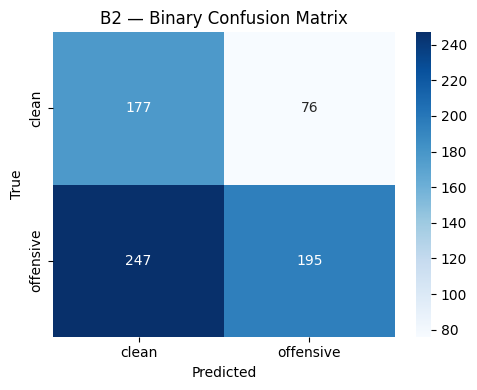

,Model,Binary Macro-F1,AP Offensive
0,DarijaToxicityDetector,0.5349,0.7593


In [22]:

# ==========================================
# PART B2 — DARIJA TOXICITY DETECTOR
# ==========================================

import torch
import numpy as np
import pandas as pd
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import (
    f1_score, classification_report,
    confusion_matrix, average_precision_score
)
import seaborn as sns
import matplotlib.pyplot as plt

MODEL_ID = "TypicaAI/DarijaToxicityDetector"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Load pretrained model
tokenizer_B2 = AutoTokenizer.from_pretrained(MODEL_ID)
model_B2 = AutoModelForSequenceClassification.from_pretrained(MODEL_ID)

model_B2.to(device)
model_B2.eval()

print("Model labels:", model_B2.config.id2label)

# 2. Map dataset labels to binary
label_mapping = {
    "Normal": "clean",
    "Abuse": "offensive",
    "Hate": "offensive"
}

y_true = df_val["label"].map(label_mapping).tolist()
texts = df_val["tweet"].astype(str).tolist()

# 3. Batch inference
all_probs = []
batch_size = 16

with torch.inference_mode():
    for i in range(0, len(texts), batch_size):

        batch = texts[i:i + batch_size]

        inputs = tokenizer_B2(
            batch,
            padding=True,
            truncation=True,
            max_length=256,
            return_tensors="pt"
        ).to(device)

        outputs = model_B2(**inputs)
        probs = torch.softmax(outputs.logits, dim=-1)

        all_probs.extend(probs.cpu().numpy())

all_probs = np.array(all_probs)

# 4. Get predictions
id2label = {
    int(k): str(v).lower()
    for k, v in model_B2.config.id2label.items()
}

pred_ids = all_probs.argmax(axis=1)
y_pred = [id2label[int(i)] for i in pred_ids]

# 5. Evaluation
macro_f1_B2 = f1_score(
    y_true, y_pred,
    labels=["clean", "offensive"],
    average="macro"
)

offensive_idx = next(
    i for i, label in id2label.items()
    if label == "offensive"
)

ap_offensive = average_precision_score(
    np.array(y_true) == "offensive",
    all_probs[:, offensive_idx]
)

print("\n=== B2 RESULTS ===")
print("Binary Macro-F1:", round(macro_f1_B2, 4))
print("AP Offensive:", round(ap_offensive, 4))

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    labels=["clean", "offensive"],
    zero_division=0
))

# 6. Confusion matrix
cm = confusion_matrix(
    y_true, y_pred,
    labels=["clean", "offensive"]
)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["clean", "offensive"],
    yticklabels=["clean", "offensive"]
)
plt.title("B2 — Binary Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

# Save
results_B2 = pd.DataFrame([{
    "Model": "DarijaToxicityDetector",
    "Binary Macro-F1": macro_f1_B2,
    "AP Offensive": ap_offensive
}])

results_B2.to_csv(
    "/kaggle/working/results_B2.csv",
    index=False
)

display(results_B2.round(4))


In [28]:

# ============================================
# PR-AUC — BASELINE + ZERO-SHOT NLI
# ============================================

import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve, auc

CLASSES = ["Abuse", "Hate", "Normal"]

def calculate_pr_auc(y_true, scores, classes):
    result = {}

    for i, label in enumerate(classes):
        y_binary = (np.array(y_true) == label).astype(int)

        precision, recall, _ = precision_recall_curve(
            y_binary, scores[:, i]
        )

        result[f"PR-AUC {label}"] = auc(recall, precision)

    return result


results_pr = []

# ============================================
# PART A — BASELINE (LR + SVM)
# ============================================

for name, model in trained_models_A.items():

    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_val)
    else:
        scores = model.decision_function(X_val)

    indices = [
        list(model.classes_).index(c)
        for c in CLASSES
    ]

    scores = scores[:, indices]

    results_pr.append({
        "Part": "A - Baseline",
        "Model": name,
        **calculate_pr_auc(y_val, scores, CLASSES)
    })


# ============================================
# PART B1 — ZERO-SHOT NLI
# ============================================

texts = df_val["tweet"].astype(str).tolist()

for language, descriptions in hypotheses.items():

    labels = list(descriptions.values())

    outputs = nli(
        texts,
        candidate_labels=labels,
        hypothesis_template="Ce texte est {}.",
        multi_label=False,
        batch_size=16,
        truncation=True,
        max_length=128
    )

    if isinstance(outputs, dict):
        outputs = [outputs]

    scores = np.array([
        [
            dict(zip(o["labels"], o["scores"]))[label]
            for label in labels
        ]
        for o in outputs
    ])

    results_pr.append({
        "Part": "B1 - Zero-Shot",
        "Model": language,
        **calculate_pr_auc(y_val, scores, CLASSES)
    })


# ============================================
# FINAL COMPARISON
# ============================================

pr_auc_comparison = pd.DataFrame(results_pr)

print("PR-AUC — BASELINE & ZERO-SHOT")
display(pr_auc_comparison.round(4))

pr_auc_comparison.to_csv(
    "/kaggle/working/pr_auc_baseline_zeroshot.csv",
    index=False
)


PR-AUC — BASELINE & ZERO-SHOT


,Part,Model,PR-AUC Abuse,PR-AUC Hate,PR-AUC Normal
0,A - Baseline,Logistic Regression,0.9582,0.7655,0.9235
1,A - Baseline,Linear SVM,0.9567,0.7081,0.9198
2,B1 - Zero-Shot,Arabic,0.6288,0.2622,0.6000
3,B1 - Zero-Shot,French,0.5948,0.2934,0.4424
4,B1 - Zero-Shot,English,0.5813,0.2919,0.4504


# Partie C — Deep Learning from Scratch

***Étape C.1 — Vocabulary Construction & OOV Analysis***

In [23]:

# ==========================================
# PART C — VOCABULARY & OOV ANALYSIS
# ==========================================

from collections import Counter
import pandas as pd
import numpy as np

# 1. Tokenization
def tokenize(text):
    return str(text).split()

train_tokens = df_train["clean_tweet"].apply(tokenize)
val_tokens = df_val["clean_tweet"].apply(tokenize)
test_tokens = df_test["clean_tweet"].apply(tokenize)

# 2. Vocabulary from TRAIN only
word_counts = Counter(
    word for tokens in train_tokens for word in tokens
)

MIN_FREQ = 2

vocab = {"<PAD>": 0, "<UNK>": 1}

for word, freq in word_counts.most_common():
    if freq >= MIN_FREQ:
        vocab[word] = len(vocab)

print("Vocabulary size:", len(vocab))
print("Unique words in train:", len(word_counts))

# 3. OOV rate
def calculate_oov(tokenized_texts, vocabulary):
    total = 0
    unknown = 0

    for tokens in tokenized_texts:
        total += len(tokens)
        unknown += sum(w not in vocabulary for w in tokens)

    return 100 * unknown / total if total else 0

oov_results = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "OOV Rate (%)": [
        calculate_oov(train_tokens, vocab),
        calculate_oov(val_tokens, vocab),
        calculate_oov(test_tokens, vocab)
    ]
})

display(oov_results.round(2))

# 4. Sequence length
lengths = train_tokens.apply(len)

MAX_LEN = int(np.percentile(lengths, 95))

print("\n95th percentile:", MAX_LEN)
print("Maximum sequence length:", MAX_LEN)

# 5. Convert texts to sequences
def encode_text(tokens):
    ids = [vocab.get(w, 1) for w in tokens[:MAX_LEN]]
    return ids + [0] * (MAX_LEN - len(ids))

X_train_seq = np.array(
    train_tokens.apply(encode_text).tolist()
)
X_val_seq = np.array(
    val_tokens.apply(encode_text).tolist()
)
X_test_seq = np.array(
    test_tokens.apply(encode_text).tolist()
)

label2id = {"Abuse": 0, "Hate": 1, "Normal": 2}
id2label = {v: k for k, v in label2id.items()}

y_train_seq = df_train["label"].map(label2id).values
y_val_seq = df_val["label"].map(label2id).values
y_test_seq = df_test["label"].map(label2id).values

print("\nTrain sequences:", X_train_seq.shape)
print("Validation sequences:", X_val_seq.shape)
print("Test sequences:", X_test_seq.shape)

print("\nData ready for Deep Learning!")


Vocabulary size: 6554
Unique words in train: 23034


,Split,OOV Rate (%)
0,Train,27.61
1,Validation,40.59
2,Test,39.47



95th percentile: 46
Maximum sequence length: 46

Train sequences: (3240, 46)
Validation sequences: (695, 46)
Test sequences: (699, 46)

Data ready for Deep Learning!


**BiLSTM vs BiLSTM + Attention**

In [24]:

# ==================================================
# PART C1 & C2 — BiLSTM vs BiLSTM + ATTENTION
# ==================================================

import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score, classification_report, average_precision_score

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. DataLoaders
train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train_seq, dtype=torch.long),
        torch.tensor(y_train_seq, dtype=torch.long)
    ),
    batch_size=64, shuffle=True
)

val_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_val_seq, dtype=torch.long),
        torch.tensor(y_val_seq, dtype=torch.long)
    ),
    batch_size=128
)

# 2. BiLSTM with optional Attention
class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, attention=False):
        super().__init__()
        self.use_attention = attention

        self.embedding = nn.Embedding(
            vocab_size, 128, padding_idx=0
        )
        self.lstm = nn.LSTM(
            128, 64,
            batch_first=True,
            bidirectional=True
        )
        if attention:
            self.attention = nn.Linear(128, 1)

        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(128, 3)

    def forward(self, x):
        emb = self.embedding(x)
        output, _ = self.lstm(emb)
        mask = x != 0

        if self.use_attention:
            scores = self.attention(output).squeeze(-1)
            scores = scores.masked_fill(~mask, -1e9)
            weights = torch.softmax(scores, dim=1)
            context = torch.sum(
                output * weights.unsqueeze(-1), dim=1
            )
        else:
            lengths = mask.sum(dim=1).clamp(min=1)
            idx = (lengths - 1).long()
            forward_last = output[
                torch.arange(len(x), device=x.device),
                idx, :64
            ]
            backward_last = output[:, 0, 64:]
            context = torch.cat(
                [forward_last, backward_last], dim=1
            )

        return self.fc(self.dropout(context))


# 3. Class weights from Train
counts = np.bincount(y_train_seq, minlength=3)
weights = len(y_train_seq) / (3 * counts)

class_weights = torch.tensor(
    weights, dtype=torch.float32, device=device
)

# 4. Training + Early Stopping
def train_model(name, attention=False):
    model = BiLSTMClassifier(
        len(vocab), attention=attention
    ).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=0.001
    )
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    best_f1 = -1
    best_state = None
    patience = 2
    no_improvement = 0

    for epoch in range(1, 7):
        model.train()
        total_loss = 0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        model.eval()
        preds, probs, labels = [], [], []

        with torch.inference_mode():
            for xb, yb in val_loader:
                logits = model(xb.to(device))
                p = torch.softmax(logits, dim=1).cpu().numpy()
                probs.extend(p)
                preds.extend(p.argmax(axis=1))
                labels.extend(yb.numpy())

        score = f1_score(labels, preds, average="macro")

        print(
            f"{name} | Epoch {epoch} | "
            f"Loss: {total_loss/len(train_loader):.4f} | "
            f"Macro-F1: {score:.4f}"
        )

        if score > best_f1:
            best_f1 = score
            best_state = copy.deepcopy(model.state_dict())
            no_improvement = 0
        else:
            no_improvement += 1
            if no_improvement >= patience:
                print("Early stopping")
                break

    model.load_state_dict(best_state)
    model.eval()

    all_probs = []
    with torch.inference_mode():
        for xb, _ in val_loader:
            p = torch.softmax(
                model(xb.to(device)), dim=1
            )
            all_probs.extend(p.cpu().numpy())

    all_probs = np.array(all_probs)
    y_pred = all_probs.argmax(axis=1)

    macro = f1_score(y_val_seq, y_pred, average="macro")
    hate = f1_score(
        y_val_seq == 1, y_pred == 1, zero_division=0
    )

    result = {
        "Model": name,
        "Macro-F1": macro,
        "Hate F1": hate
    }

    for i, label in enumerate(["Abuse", "Hate", "Normal"]):
        result[f"AP {label}"] = average_precision_score(
            y_val_seq == i, all_probs[:, i]
        )

    print("\n", name)
    print(classification_report(
        y_val_seq, y_pred,
        target_names=["Abuse", "Hate", "Normal"],
        zero_division=0
    ))

    torch.save(
        model.state_dict(),
        f"/kaggle/working/{name.replace(' ', '_')}.pt"
    )

    return result, model


# 5. Train both architectures
results_C = []
trained_models_C = {}

for name, att in [
    ("C1 BiLSTM", False),
    ("C2 BiLSTM Attention", True)
]:
    result, model = train_model(name, attention=att)
    results_C.append(result)
    trained_models_C[name] = model

# 6. Comparison
comparison_C = pd.DataFrame(results_C).sort_values(
    "Macro-F1", ascending=False
)

print("\nDEEP LEARNING COMPARISON — VALIDATION")
display(comparison_C.round(4))

comparison_C.to_csv(
    "/kaggle/working/results_C1_C2.csv",
    index=False
)


C1 BiLSTM | Epoch 1 | Loss: 1.0136 | Macro-F1: 0.5120
C1 BiLSTM | Epoch 2 | Loss: 0.8622 | Macro-F1: 0.5970
C1 BiLSTM | Epoch 3 | Loss: 0.6849 | Macro-F1: 0.6700
C1 BiLSTM | Epoch 4 | Loss: 0.5421 | Macro-F1: 0.6931
C1 BiLSTM | Epoch 5 | Loss: 0.4112 | Macro-F1: 0.7380
C1 BiLSTM | Epoch 6 | Loss: 0.2995 | Macro-F1: 0.7222

 C1 BiLSTM
              precision    recall  f1-score   support

       Abuse       0.86      0.84      0.85       340
        Hate       0.56      0.64      0.59       102
      Normal       0.78      0.76      0.77       253

    accuracy                           0.78       695
   macro avg       0.73      0.75      0.74       695
weighted avg       0.79      0.78      0.78       695

C2 BiLSTM Attention | Epoch 1 | Loss: 1.0086 | Macro-F1: 0.5014
C2 BiLSTM Attention | Epoch 2 | Loss: 0.7988 | Macro-F1: 0.6139
C2 BiLSTM Attention | Epoch 3 | Loss: 0.6666 | Macro-F1: 0.6437
C2 BiLSTM Attention | Epoch 4 | Loss: 0.5367 | Macro-F1: 0.7013
C2 BiLSTM Attention | Epoch

,Model,Macro-F1,Hate F1,AP Abuse,AP Hate,AP Normal
0,C1 BiLSTM,0.7380,0.5936,0.9312,0.5891,0.8782
1,C2 BiLSTM Attention,0.7152,0.5484,0.9171,0.5655,0.8784


**Mini-Transformer et Char-CNN**

In [25]:

# =====================================================
# PART C3 & C4 — MINI-TRANSFORMER + CHAR-CNN
# =====================================================

import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from collections import Counter
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score, average_precision_score, classification_report

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
CLASSES = ["Abuse", "Hate", "Normal"]

# =====================================================
# 1. MINI-TRANSFORMER (2 layers, d_model=128, 4 heads)
# =====================================================

class MiniTransformer(nn.Module):
    def __init__(self, vocab_size, max_len, positional=True):
        super().__init__()
        self.positional = positional
        self.embedding = nn.Embedding(vocab_size, 128, padding_idx=0)
        self.position = nn.Embedding(max_len, 128)

        layer = nn.TransformerEncoderLayer(
            d_model=128,
            nhead=4,
            dim_feedforward=256,
            dropout=0.2,
            batch_first=True,
            norm_first=False
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=2)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(128, 3)

    def forward(self, x):
        batch, length = x.shape
        positions = torch.arange(length, device=x.device)
        emb = self.embedding(x)

        if self.positional:
            emb = emb + self.position(positions).unsqueeze(0)

        mask = x == 0
        hidden = self.encoder(emb, src_key_padding_mask=mask)

        valid = (~mask).unsqueeze(-1)
        pooled = (hidden * valid).sum(dim=1) / valid.sum(dim=1).clamp(min=1)

        return self.fc(self.dropout(pooled))


# =====================================================
# 2. CHARACTER VOCABULARY — TRAIN ONLY
# =====================================================

train_texts = df_train["clean_tweet"].astype(str).tolist()
val_texts = df_val["clean_tweet"].astype(str).tolist()

char_counts = Counter(c for text in train_texts for c in text)

char_vocab = {"<PAD>": 0, "<UNK>": 1}
for char, count in char_counts.most_common():
    if count >= 2:
        char_vocab[char] = len(char_vocab)

MAX_CHAR_LEN = max(
    16, int(np.percentile([len(t) for t in train_texts], 95))
)

def encode_chars(text):
    ids = [char_vocab.get(c, 1) for c in text[:MAX_CHAR_LEN]]
    return ids + [0] * (MAX_CHAR_LEN - len(ids))

X_train_char = np.array([encode_chars(t) for t in train_texts])
X_val_char = np.array([encode_chars(t) for t in val_texts])

print("Character vocabulary:", len(char_vocab))
print("Max character length:", MAX_CHAR_LEN)


# =====================================================
# 3. CHARACTER CNN
# =====================================================

class CharCNN(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size, 64, padding_idx=0
        )

        self.convs = nn.ModuleList([
            nn.Conv1d(64, 128, kernel_size=k)
            for k in [3, 4, 5]
        ])

        self.dropout = nn.Dropout(0.4)
        self.fc = nn.Linear(128 * 3, 3)

    def forward(self, x):
        emb = self.embedding(x).transpose(1, 2)
        features = []

        for conv in self.convs:
            h = torch.relu(conv(emb))
            features.append(torch.max(h, dim=2).values)

        combined = torch.cat(features, dim=1)
        return self.fc(self.dropout(combined))


# =====================================================
# 4. GENERIC TRAINING FUNCTION
# =====================================================

def train_C_model(name, model, Xtr, Xv, epochs=6):

    model = model.to(device)

    train_dl = DataLoader(
        TensorDataset(
            torch.tensor(Xtr, dtype=torch.long),
            torch.tensor(y_train_seq, dtype=torch.long)
        ),
        batch_size=64,
        shuffle=True
    )

    val_dl = DataLoader(
        TensorDataset(
            torch.tensor(Xv, dtype=torch.long),
            torch.tensor(y_val_seq, dtype=torch.long)
        ),
        batch_size=128
    )

    counts = np.bincount(y_train_seq, minlength=3)
    weights = torch.tensor(
        len(y_train_seq) / (3 * counts),
        dtype=torch.float32, device=device
    )

    criterion = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)

    best_f1 = -1
    best_state = None
    patience_counter = 0

    for epoch in range(1, epochs + 1):

        model.train()
        total_loss = 0

        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        model.eval()
        predictions = []

        with torch.inference_mode():
            for xb, _ in val_dl:
                logits = model(xb.to(device))
                predictions.extend(
                    logits.argmax(dim=1).cpu().numpy()
                )

        macro = f1_score(
            y_val_seq, predictions, average="macro"
        )

        print(
            f"{name} | Epoch {epoch} | "
            f"Loss={total_loss/len(train_dl):.4f} | "
            f"Macro-F1={macro:.4f}"
        )

        if macro > best_f1:
            best_f1 = macro
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= 2:
                print("Early stopping")
                break

    # Restore best weights
    model.load_state_dict(best_state)
    model.eval()

    probabilities = []

    with torch.inference_mode():
        for xb, _ in val_dl:
            probs = torch.softmax(model(xb.to(device)), dim=1)
            probabilities.extend(probs.cpu().numpy())

    probabilities = np.array(probabilities)
    preds = probabilities.argmax(axis=1)

    result = {
        "Model": name,
        "Macro-F1": f1_score(
            y_val_seq, preds, average="macro"
        ),
        "Hate F1": f1_score(
            y_val_seq == 1, preds == 1, zero_division=0
        )
    }

    for i, label in enumerate(CLASSES):
        result[f"AP {label}"] = average_precision_score(
            y_val_seq == i, probabilities[:, i]
        )

    print("\n", name)
    print(classification_report(
        y_val_seq, preds,
        target_names=CLASSES,
        zero_division=0
    ))

    torch.save(
        model.state_dict(),
        f"/kaggle/working/{name.replace(' ', '_')}.pt"
    )

    return result, model


# =====================================================
# 5. TRAIN C3 + C4
# =====================================================

result_C3, model_C3 = train_C_model(
    "C3 Mini Transformer",
    MiniTransformer(len(vocab), X_train_seq.shape[1]),
    X_train_seq,
    X_val_seq
)

result_C4, model_C4 = train_C_model(
    "C4 Char CNN",
    CharCNN(len(char_vocab)),
    X_train_char,
    X_val_char
)

# =====================================================
# 6. FINAL COMPARISON — C1 TO C4
# =====================================================

results_C.extend([result_C3, result_C4])

comparison_C = pd.DataFrame(results_C).sort_values(
    "Macro-F1", ascending=False
).reset_index(drop=True)

print("\nDEEP LEARNING COMPARISON — C1 TO C4")
display(comparison_C.round(4))

comparison_C.to_csv(
    "/kaggle/working/results_C.csv",
    index=False
)

trained_models_C["C3 Mini Transformer"] = model_C3
trained_models_C["C4 Char CNN"] = model_C4


Character vocabulary: 280
Max character length: 263
C3 Mini Transformer | Epoch 1 | Loss=0.9511 | Macro-F1=0.6025
C3 Mini Transformer | Epoch 2 | Loss=0.7599 | Macro-F1=0.6232
C3 Mini Transformer | Epoch 3 | Loss=0.6179 | Macro-F1=0.6962
C3 Mini Transformer | Epoch 4 | Loss=0.4815 | Macro-F1=0.6836
C3 Mini Transformer | Epoch 5 | Loss=0.3432 | Macro-F1=0.6735
Early stopping

 C3 Mini Transformer
              precision    recall  f1-score   support

       Abuse       0.79      0.89      0.83       340
        Hate       0.48      0.56      0.52       102
      Normal       0.85      0.65      0.74       253

    accuracy                           0.75       695
   macro avg       0.71      0.70      0.70       695
weighted avg       0.76      0.75      0.75       695

C4 Char CNN | Epoch 1 | Loss=1.0515 | Macro-F1=0.6469
C4 Char CNN | Epoch 2 | Loss=0.7882 | Macro-F1=0.6341
C4 Char CNN | Epoch 3 | Loss=0.6912 | Macro-F1=0.6688
C4 Char CNN | Epoch 4 | Loss=0.6422 | Macro-F1=0.7264
C4 C

,Model,Macro-F1,Hate F1,AP Abuse,AP Hate,AP Normal
0,C1 BiLSTM,0.7380,0.5936,0.9312,0.5891,0.8782
1,C4 Char CNN,0.7324,0.5852,0.9357,0.5849,0.8738
2,C2 BiLSTM Attention,0.7152,0.5484,0.9171,0.5655,0.8784
3,C3 Mini Transformer,0.6962,0.5182,0.9008,0.4757,0.8476


# Ablation du Positional Encoding
vérifier si le Positional Encoding améliore les performances du Mini-Transformer.

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
Mini Transformer No PE | Epoch 1 | Loss=0.9200 | Macro-F1=0.6486
Mini Transformer No PE | Epoch 2 | Loss=0.7075 | Macro-F1=0.7038
Mini Transformer No PE | Epoch 3 | Loss=0.5634 | Macro-F1=0.7539
Mini Transformer No PE | Epoch 4 | Loss=0.4348 | Macro-F1=0.7240
Mini Transformer No PE | Epoch 5 | Loss=0.3288 | Macro-F1=0.7688
Mini Transformer No PE | Epoch 6 | Loss=0.2307 | Macro-F1=0.7432

 Mini Transformer No PE
              precision    recall  f1-score   support

       Abuse       0.85      0.88      0.87       340
        Hate       0.65      0.67      0.66       102
      Normal       0.81      0.76      0.78       253

    accuracy                           0.81       695
   macro avg       0.77      0.77      0.77       695
weighted avg       0.81      0.81      0.81       695


POSITIONAL ENCODING ABLATION


,Model,Macro-F1,Hate F1,AP Abuse,AP Hate,AP Normal
0,With Positional Encoding,0.6962,0.5182,0.9008,0.4757,0.8476
1,Without Positional Encoding,0.7688,0.6570,0.9160,0.6462,0.8585


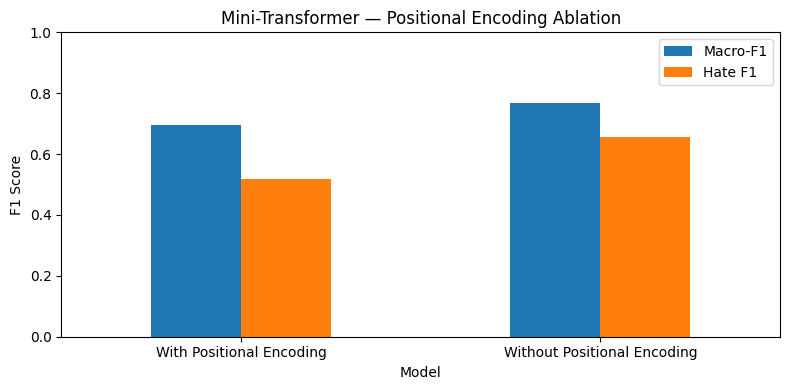

In [48]:

# =====================================================
# C3 — POSITIONAL ENCODING ABLATION
# =====================================================

import numpy as np
import pandas as pd
import torch

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Mini-Transformer WITHOUT Positional Encoding
model_no_pe = MiniTransformer(
    vocab_size=len(vocab),
    max_len=X_train_seq.shape[1],
    positional=False
)

# Train and evaluate
result_no_pe, trained_no_pe = train_C_model(
    "Mini Transformer No PE",
    model_no_pe,
    X_train_seq,
    X_val_seq,
    epochs=6
)

# Compare with previous model
result_with_pe = next(
    r for r in results_C
    if r["Model"] == "C3 Mini Transformer"
)

comparison_pe = pd.DataFrame([
    {
        **result_with_pe,
        "Model": "With Positional Encoding"
    },
    {
        **result_no_pe,
        "Model": "Without Positional Encoding"
    }
])

print("\nPOSITIONAL ENCODING ABLATION")
display(comparison_pe.round(4))

# Visualization
import matplotlib.pyplot as plt

comparison_pe.set_index("Model")[
    ["Macro-F1", "Hate F1"]
].plot(
    kind="bar",
    figsize=(8, 4),
    rot=0
)

plt.title("Mini-Transformer — Positional Encoding Ablation")
plt.ylabel("F1 Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# Save results
comparison_pe.to_csv(
    "/kaggle/working/positional_encoding_ablation.csv",
    index=False
)


# Comparaison des embeddings : Random vs Word2Vec vs FastText

In [50]:

# ==========================================
# FIX — BILSTM DATALOADERS
# ==========================================

from torch.utils.data import TensorDataset, DataLoader
import torch

train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train_seq, dtype=torch.long),
        torch.tensor(y_train_seq, dtype=torch.long)
    ),
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_val_seq, dtype=torch.long),
        torch.tensor(y_val_seq, dtype=torch.long)
    ),
    batch_size=128,
    shuffle=False
)

print("BiLSTM DataLoaders ready!")
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Batch elements:", len(next(iter(train_loader))))


BiLSTM DataLoaders ready!
Train batches: 51
Validation batches: 6
Batch elements: 2


In [51]:

# =====================================================
# PART C — EMBEDDING ABLATION: RANDOM / W2V / FASTTEXT
# =====================================================

import copy
import random
import numpy as np
import pandas as pd
import torch
from gensim.models import Word2Vec, FastText

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# 1. Train embeddings on TRAIN only
sentences = df_train["clean_tweet"].astype(str).str.split().tolist()

embedding_models = {
    "Word2Vec": Word2Vec(
        sentences=sentences,
        vector_size=128,
        window=5,
        min_count=1,
        workers=1,
        sg=1,
        epochs=10,
        seed=SEED
    ),
    "FastText": FastText(
        sentences=sentences,
        vector_size=128,
        window=5,
        min_count=1,
        workers=1,
        sg=1,
        epochs=10,
        seed=SEED
    )
}

# 2. Convert embeddings into matrices
def make_embedding_matrix(embedding_model):
    matrix = np.random.normal(
        0, 0.02, (len(vocab), 128)
    ).astype(np.float32)

    matrix[0] = 0  # Padding

    for word, idx in vocab.items():
        if idx < 2:
            continue

        if word in embedding_model.wv:
            matrix[idx] = embedding_model.wv[word]

    return torch.tensor(matrix, dtype=torch.float32)

# 3. Train BiLSTM with pretrained embeddings
embedding_results = []

for name, emb_model in embedding_models.items():

    print(f"\n========== {name} ==========")

    torch.manual_seed(SEED)

    model = BiLSTMClassifier(
        vocab_size=len(vocab),
        attention=False
    ).to(device)

    matrix = make_embedding_matrix(emb_model)

    model.embedding.weight.data.copy_(
        matrix.to(device)
    )

    # Fine-tune embeddings during training
    model.embedding.weight.requires_grad = True

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=0.001
    )

    criterion = torch.nn.CrossEntropyLoss(
        weight=class_weights
    )

    best_f1 = -1
    best_state = None
    patience = 0

    for epoch in range(1, 7):
        model.train()
        total_loss = 0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        model.eval()
        predictions = []
        probabilities = []

        with torch.inference_mode():
            for xb, yb in val_loader:
                logits = model(xb.to(device))
                probs = torch.softmax(logits, dim=1)
                probabilities.extend(probs.cpu().numpy())
                predictions.extend(
                    logits.argmax(dim=1).cpu().numpy()
                )

        score = f1_score(
            y_val_seq, predictions, average="macro"
        )

        print(
            f"Epoch {epoch} | "
            f"Macro-F1={score:.4f}"
        )

        if score > best_f1:
            best_f1 = score
            best_state = copy.deepcopy(model.state_dict())
            patience = 0
        else:
            patience += 1
            if patience >= 2:
                break

    model.load_state_dict(best_state)
    model.eval()

    all_probs = []

    with torch.inference_mode():
        for xb, _ in val_loader:
            probs = torch.softmax(
                model(xb.to(device)), dim=1
            )
            all_probs.extend(probs.cpu().numpy())

    all_probs = np.array(all_probs)
    preds = all_probs.argmax(axis=1)

    result = {
        "Embedding": name,
        "Macro-F1": f1_score(
            y_val_seq, preds, average="macro"
        ),
        "Hate F1": f1_score(
            y_val_seq == 1, preds == 1,
            zero_division=0
        )
    }

    for i, label in enumerate(["Abuse", "Hate", "Normal"]):
        precision, recall, _ = precision_recall_curve(
            y_val_seq == i, all_probs[:, i]
        )
        result[f"PR-AUC {label}"] = auc(recall, precision)

    embedding_results.append(result)

    torch.save(
        model.state_dict(),
        f"/kaggle/working/BiLSTM_{name}.pt"
    )

# 4. Add previous random embedding baseline
embedding_results.insert(0, {
    "Embedding": "Random",
    "Macro-F1": 0.7380,
    "Hate F1": 0.5936,
    "PR-AUC Abuse": 0.9310,
    "PR-AUC Hate": 0.5847,
    "PR-AUC Normal": 0.8780
})

embedding_comparison = pd.DataFrame(
    embedding_results
).sort_values("Macro-F1", ascending=False)

print("\nEMBEDDING COMPARISON")
display(embedding_comparison.round(4))

embedding_comparison.to_csv(
    "/kaggle/working/embedding_comparison.csv",
    index=False
)



========== Word2Vec ==========
Epoch 1 | Macro-F1=0.5927
Epoch 2 | Macro-F1=0.6403
Epoch 3 | Macro-F1=0.6572
Epoch 4 | Macro-F1=0.7063
Epoch 5 | Macro-F1=0.7417
Epoch 6 | Macro-F1=0.7543

========== FastText ==========
Epoch 1 | Macro-F1=0.5834
Epoch 2 | Macro-F1=0.6053
Epoch 3 | Macro-F1=0.6516
Epoch 4 | Macro-F1=0.6818
Epoch 5 | Macro-F1=0.7175
Epoch 6 | Macro-F1=0.7682

EMBEDDING COMPARISON


,Embedding,Macro-F1,Hate F1,PR-AUC Abuse,PR-AUC Hate,PR-AUC Normal
2,FastText,0.7682,0.6320,0.9179,0.6197,0.9120
1,Word2Vec,0.7543,0.6147,0.9164,0.6175,0.9015
0,Random,0.7380,0.5936,0.9310,0.5847,0.8780


In [26]:

from sklearn.metrics import precision_recall_curve, auc
import numpy as np
import pandas as pd
import torch

CLASSES = ["Abuse", "Hate", "Normal"]

# Préparer les données
word_val = torch.tensor(X_val_seq, dtype=torch.long)
char_val = torch.tensor(X_val_char, dtype=torch.long)

results_pr_auc = []

for name, model in trained_models_C.items():
    model.eval()

    X = char_val if "Char CNN" in name else word_val

    probabilities = []

    with torch.inference_mode():
        for batch in X.split(128):
            logits = model(batch.to(device))
            probs = torch.softmax(logits, dim=1)
            probabilities.append(probs.cpu().numpy())

    probabilities = np.vstack(probabilities)

    row = {"Model": name}

    for i, label in enumerate(CLASSES):
        y_binary = (y_val_seq == i).astype(int)

        precision, recall, _ = precision_recall_curve(
            y_binary, probabilities[:, i]
        )

        row[f"PR-AUC {label}"] = auc(recall, precision)

    results_pr_auc.append(row)

pr_auc_df = pd.DataFrame(results_pr_auc)

print("PR-AUC BY CLASS — VALIDATION")
display(pr_auc_df.round(4))


PR-AUC BY CLASS — VALIDATION


,Model,PR-AUC Abuse,PR-AUC Hate,PR-AUC Normal
0,C1 BiLSTM,0.9310,0.5847,0.8780
1,C2 BiLSTM Attention,0.9168,0.5609,0.8782
2,C3 Mini Transformer,0.9006,0.4704,0.8473
3,C4 Char CNN,0.9356,0.5798,0.8736


# Reproducibility : 3 Random Seeds

In [52]:

# =====================================================
# REPRODUCIBILITY — FASTTEXT + BiLSTM (3 SEEDS)
# =====================================================

import copy
import random
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    f1_score, precision_recall_curve, auc
)

SEEDS = [42, 123, 2026]
CLASSES = ["Abuse", "Hate", "Normal"]

# FastText embedding matrix
fasttext_matrix = make_embedding_matrix(
    embedding_models["FastText"]
)

seed_results = []

for seed in SEEDS:

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    print(f"\n========== SEED {seed} ==========")

    model = BiLSTMClassifier(
        vocab_size=len(vocab),
        attention=False
    ).to(device)

    model.embedding.weight.data.copy_(
        fasttext_matrix.to(device)
    )

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=0.001
    )
    criterion = torch.nn.CrossEntropyLoss(
        weight=class_weights
    )

    best_macro = -1
    best_state = None
    patience = 0

    # Fresh DataLoader for reproducible shuffling
    generator = torch.Generator().manual_seed(seed)

    train_dl = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(
            torch.tensor(X_train_seq, dtype=torch.long),
            torch.tensor(y_train_seq, dtype=torch.long)
        ),
        batch_size=64,
        shuffle=True,
        generator=generator
    )

    val_dl = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(
            torch.tensor(X_val_seq, dtype=torch.long),
            torch.tensor(y_val_seq, dtype=torch.long)
        ),
        batch_size=128
    )

    for epoch in range(1, 7):
        model.train()

        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

        model.eval()
        val_probs = []

        with torch.inference_mode():
            for xb, _ in val_dl:
                probs = torch.softmax(
                    model(xb.to(device)), dim=1
                )
                val_probs.append(probs.cpu().numpy())

        val_probs = np.vstack(val_probs)
        preds = val_probs.argmax(axis=1)
        macro = f1_score(y_val_seq, preds, average="macro")

        print(f"Epoch {epoch} | Macro-F1={macro:.4f}")

        if macro > best_macro:
            best_macro = macro
            best_state = copy.deepcopy(model.state_dict())
            patience = 0
        else:
            patience += 1
            if patience >= 2:
                break

    model.load_state_dict(best_state)
    model.eval()

    all_probs = []
    with torch.inference_mode():
        for xb, _ in val_dl:
            all_probs.append(
                torch.softmax(model(xb.to(device)), dim=1)
                .cpu().numpy()
            )

    all_probs = np.vstack(all_probs)
    preds = all_probs.argmax(axis=1)

    row = {
        "Seed": seed,
        "Macro-F1": f1_score(
            y_val_seq, preds, average="macro"
        ),
        "Hate F1": f1_score(
            y_val_seq == 1, preds == 1, zero_division=0
        )
    }

    for i, label in enumerate(CLASSES):
        p, r, _ = precision_recall_curve(
            y_val_seq == i, all_probs[:, i]
        )
        row[f"PR-AUC {label}"] = auc(r, p)

    seed_results.append(row)

    torch.save(
        model.state_dict(),
        f"/kaggle/working/FastText_BiLSTM_seed{seed}.pt"
    )

# Final results
seeds_df = pd.DataFrame(seed_results)

print("\nRESULTS — 3 SEEDS")
display(seeds_df.round(4))

print("\nMEAN ± STANDARD DEVIATION")
summary_seeds = seeds_df.drop(columns="Seed").agg(
    ["mean", "std"]
)
display(summary_seeds.round(4))

seeds_df.to_csv(
    "/kaggle/working/fasttext_3seeds.csv", index=False
)



========== SEED 42 ==========
Epoch 1 | Macro-F1=0.5837
Epoch 2 | Macro-F1=0.6061
Epoch 3 | Macro-F1=0.6435
Epoch 4 | Macro-F1=0.7154
Epoch 5 | Macro-F1=0.7524
Epoch 6 | Macro-F1=0.7740

========== SEED 123 ==========
Epoch 1 | Macro-F1=0.5875
Epoch 2 | Macro-F1=0.6125
Epoch 3 | Macro-F1=0.6372
Epoch 4 | Macro-F1=0.6821
Epoch 5 | Macro-F1=0.7271
Epoch 6 | Macro-F1=0.7633

========== SEED 2026 ==========
Epoch 1 | Macro-F1=0.5458
Epoch 2 | Macro-F1=0.6238
Epoch 3 | Macro-F1=0.6251
Epoch 4 | Macro-F1=0.6927
Epoch 5 | Macro-F1=0.7503
Epoch 6 | Macro-F1=0.7593

RESULTS — 3 SEEDS


,Seed,Macro-F1,Hate F1,PR-AUC Abuse,PR-AUC Hate,PR-AUC Normal
0,42,0.7740,0.6457,0.9283,0.6497,0.9043
1,123,0.7633,0.6283,0.9288,0.6279,0.9015
2,2026,0.7593,0.6180,0.9246,0.6348,0.9050



MEAN ± STANDARD DEVIATION


,Macro-F1,Hate F1,PR-AUC Abuse,PR-AUC Hate,PR-AUC Normal
mean,0.7655,0.6307,0.9272,0.6375,0.9036
std,0.0076,0.0140,0.0023,0.0111,0.0019



## Partie D — DarijaBERT : Embeddings contextuels et classification

- Extraction des embeddings CLS et Mean Pooling.
- Utilisation de DarijaBERT préentraîné et gelé (Frozen).
- Classification avec Logistic Regression.
- Comparaison des performances : Macro-F1, Hate F1 et PR-AUC.

**FROZEN DARIJABERT: CLS VS MEAN POOLING**

In [29]:

# ===================================================
# PART D1 — FROZEN DARIJABERT: CLS VS MEAN POOLING
# ===================================================

import gc
import numpy as np
import pandas as pd
import torch

from transformers import AutoTokenizer, AutoModel
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score, classification_report,
    precision_recall_curve, auc
)
from torch.utils.data import DataLoader

MODEL_ID = "SI2M-Lab/DarijaBERT"
CLASSES = ["Abuse", "Hate", "Normal"]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Load frozen DarijaBERT
tokenizer_D = AutoTokenizer.from_pretrained(MODEL_ID)
bert_D = AutoModel.from_pretrained(MODEL_ID).to(device)
bert_D.eval()

for p in bert_D.parameters():
    p.requires_grad = False

# 2. Extract CLS and Mean Pooling embeddings
def extract_embeddings(texts, batch_size=32):
    cls_vectors, mean_vectors = [], []

    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]

        inputs = tokenizer_D(
            batch,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        ).to(device)

        with torch.inference_mode():
            hidden = bert_D(**inputs).last_hidden_state

            # CLS token representation
            cls = hidden[:, 0, :]

            # Mean pooling without padding
            mask = inputs["attention_mask"].unsqueeze(-1)
            mean = (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)

        cls_vectors.append(cls.cpu().numpy())
        mean_vectors.append(mean.cpu().numpy())

    return np.vstack(cls_vectors), np.vstack(mean_vectors)

# 3. Embeddings using original tweets
train_texts = df_train["tweet"].astype(str).tolist()
val_texts = df_val["tweet"].astype(str).tolist()

print("Extracting Train embeddings...")
X_train_cls, X_train_mean = extract_embeddings(train_texts)

print("Extracting Validation embeddings...")
X_val_cls, X_val_mean = extract_embeddings(val_texts)

# 4. Train LR heads and calculate metrics
results_D1 = []
trained_models_D1 = {}

for pooling, Xtr, Xv in [
    ("CLS", X_train_cls, X_val_cls),
    ("Mean Pooling", X_train_mean, X_val_mean)
]:
    clf = LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
    clf.fit(Xtr, df_train["label"])

    pred = clf.predict(Xv)
    scores = clf.predict_proba(Xv)

    row = {
        "Model": f"DarijaBERT {pooling}",
        "Macro-F1": f1_score(
            df_val["label"], pred, average="macro"
        ),
        "Hate F1": f1_score(
            df_val["label"], pred,
            labels=["Hate"], average="macro",
            zero_division=0
        )
    }

    for label in CLASSES:
        idx = list(clf.classes_).index(label)
        precision, recall, _ = precision_recall_curve(
            (df_val["label"] == label).astype(int),
            scores[:, idx]
        )
        row[f"PR-AUC {label}"] = auc(recall, precision)

    results_D1.append(row)
    trained_models_D1[pooling] = clf

    print(f"\n=== DarijaBERT {pooling} ===")
    print(classification_report(
        df_val["label"], pred,
        labels=CLASSES, zero_division=0
    ))

# 5. Comparison
comparison_D1 = pd.DataFrame(results_D1).sort_values(
    "Macro-F1", ascending=False
)

print("\nD1 — CLS VS MEAN POOLING")
display(comparison_D1.round(4))

comparison_D1.to_csv(
    "/kaggle/working/results_D1.csv",
    index=False
)

# 6. Save classifiers and release GPU memory
import joblib

for name, clf in trained_models_D1.items():
    joblib.dump(
        clf,
        f"/kaggle/working/D1_{name.replace(' ', '_')}_LR.joblib"
    )

del bert_D
gc.collect()
torch.cuda.empty_cache()

print("\nD1 completed. Classifiers saved.")


config.json:   0%|          | 0.00/779 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/307 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/879k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.51M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  836MB            

... (2 outputs left out)

[transformers] BertModel LOAD REPORT from: SI2M-Lab/DarijaBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Extracting Train embeddings...
Extracting Validation embeddings...

=== DarijaBERT CLS ===
              precision    recall  f1-score   support

       Abuse       0.84      0.80      0.82       340
        Hate       0.44      0.57      0.50       102
      Normal       0.75      0.72      0.74       253

    accuracy                           0.74       695
   macro avg       0.68      0.70      0.68       695
weighted avg       0.75      0.74      0.74       695


=== DarijaBERT Mean Pooling ===
              precision    recall  f1-score   support

       Abuse       0.83      0.78      0.80       340
        Hate       0.45      0.61      0.51       102
      Normal       0.77      0.72      0.75       253

    accuracy                           0.73       695
   macro avg       0.68      0.70      0.69       695
weighted avg       0.75      0.73      0.74       695


D1 — CLS VS MEAN POOLING


,Model,Macro-F1,Hate F1,PR-AUC Abuse,PR-AUC Hate,PR-AUC Normal
1,DarijaBERT Mean Pooling,0.6875,0.5145,0.8833,0.4811,0.8419
0,DarijaBERT CLS,0.6850,0.4979,0.9014,0.4489,0.8315



D1 completed. Classifiers saved.


**Frozen DarijaBERT + BiLSTM + Attention**

In [30]:

# ======================================================
# D2 — FROZEN DARIJABERT + BiLSTM + ATTENTION
# ======================================================

import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn

from transformers import AutoTokenizer, AutoModel
from sklearn.metrics import (
    f1_score, classification_report,
    precision_recall_curve, auc
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)

MODEL_ID = "SI2M-Lab/DarijaBERT"
CLASSES = ["Abuse", "Hate", "Normal"]
MAX_LENGTH = 96
BATCH_SIZE = 16

# 1. Frozen DarijaBERT
tokenizer_D2 = AutoTokenizer.from_pretrained(MODEL_ID)
bert_D2 = AutoModel.from_pretrained(MODEL_ID).to(device)
bert_D2.eval()
bert_D2.requires_grad_(False)

# 2. BiLSTM + Attention head
class DarijaAttentionHead(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
        self.lstm = nn.LSTM(
            hidden_size, 64,
            batch_first=True,
            bidirectional=True
        )
        self.attention = nn.Linear(128, 1)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(128, 3)

    def forward(self, embeddings, mask):
        outputs, _ = self.lstm(embeddings)

        scores = self.attention(outputs).squeeze(-1)
        scores = scores.masked_fill(mask == 0, -1e9)

        weights = torch.softmax(scores, dim=1)
        context = torch.sum(
            outputs * weights.unsqueeze(-1), dim=1
        )

        logits = self.fc(self.dropout(context))
        return logits, weights


head_D2 = DarijaAttentionHead(
    bert_D2.config.hidden_size
).to(device)

# 3. Data preparation
label2id = {"Abuse": 0, "Hate": 1, "Normal": 2}

train_texts = df_train["tweet"].astype(str).tolist()
val_texts = df_val["tweet"].astype(str).tolist()

y_train_D2 = df_train["label"].map(label2id).to_numpy()
y_val_D2 = df_val["label"].map(label2id).to_numpy()

counts = np.bincount(y_train_D2, minlength=3)
class_weights = torch.tensor(
    len(y_train_D2) / (3 * counts),
    dtype=torch.float32, device=device
)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(head_D2.parameters(), lr=0.001)

# 4. Batch function: frozen embeddings + trainable head
def run_batches(texts, labels, training=False):
    head_D2.train(training)

    predictions = []
    probabilities = []
    total_loss = 0

    order = np.arange(len(texts))
    if training:
        np.random.shuffle(order)

    for start in range(0, len(order), BATCH_SIZE):
        ids = order[start:start + BATCH_SIZE]
        batch_texts = [texts[i] for i in ids]

        inputs = tokenizer_D2(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        ).to(device)

        # DarijaBERT remains frozen
        with torch.no_grad():
            embeddings = bert_D2(
                **inputs
            ).last_hidden_state

        with torch.set_grad_enabled(training):
            logits, _ = head_D2(
                embeddings, inputs["attention_mask"]
            )

            if training:
                targets = torch.tensor(
                    labels[ids], dtype=torch.long,
                    device=device
                )
                loss = criterion(logits, targets)

                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    head_D2.parameters(), 1.0
                )
                optimizer.step()
                total_loss += loss.item()

        probs = torch.softmax(logits.detach(), dim=1)
        probabilities.extend(probs.cpu().numpy())

    probabilities = np.array(probabilities)

    if not training:
        predictions = probabilities.argmax(axis=1)

    return (
        total_loss,
        predictions,
        probabilities
    )


# 5. Training with early stopping
best_f1 = -1
best_state = None
patience = 0

for epoch in range(1, 5):

    loss, _, _ = run_batches(
        train_texts, y_train_D2, training=True
    )

    _, preds, probs = run_batches(
        val_texts, y_val_D2, training=False
    )

    macro = f1_score(
        y_val_D2, preds, average="macro"
    )

    print(
        f"Epoch {epoch} | "
        f"Loss: {loss:.4f} | Macro-F1: {macro:.4f}"
    )

    if macro > best_f1:
        best_f1 = macro
        best_state = copy.deepcopy(head_D2.state_dict())
        patience = 0
    else:
        patience += 1
        if patience >= 2:
            print("Early stopping")
            break

head_D2.load_state_dict(best_state)
head_D2.eval()

# 6. Final validation evaluation
_, preds, probs = run_batches(
    val_texts, y_val_D2, training=False
)

result_D2 = {
    "Model": "D2 DarijaBERT + BiLSTM Attention",
    "Macro-F1": f1_score(
        y_val_D2, preds, average="macro"
    ),
    "Hate F1": f1_score(
        y_val_D2 == 1, preds == 1,
        zero_division=0
    )
}

for i, label in enumerate(CLASSES):
    precision, recall, _ = precision_recall_curve(
        y_val_D2 == i, probs[:, i]
    )
    result_D2[f"PR-AUC {label}"] = auc(
        recall, precision
    )

print("\nD2 RESULTS")
display(pd.DataFrame([result_D2]).round(4))

print(classification_report(
    y_val_D2, preds,
    target_names=CLASSES,
    zero_division=0
))

# 7. Attention visualization on 5 validation tweets
# Prefer examples from different true labels
selected = []
for label in CLASSES:
    selected.extend(
        df_val.index[df_val["label"] == label][:2].tolist()
    )
selected = selected[:5]

for idx in selected:
    text = val_texts[idx]

    inputs = tokenizer_D2(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH
    ).to(device)

    with torch.inference_mode():
        embeddings = bert_D2(**inputs).last_hidden_state
        logits, attention = head_D2(
            embeddings, inputs["attention_mask"]
        )

    tokens = tokenizer_D2.convert_ids_to_tokens(
        inputs["input_ids"][0].cpu().tolist()
    )

    weights = attention[0].cpu().numpy()

    # Exclude special tokens for visualization
    items = [
        (token, float(weight))
        for token, weight in zip(tokens, weights)
        if token not in tokenizer_D2.all_special_tokens
    ]

    top_tokens = sorted(
        items, key=lambda x: x[1], reverse=True
    )[:10]

    print(f"\nTweet {idx}")
    print("True:", df_val.iloc[idx]["label"])
    print("Predicted:", CLASSES[logits.argmax(-1).item()])
    print("Text:", text[:250])

    display(pd.DataFrame(
        top_tokens,
        columns=["Token", "Attention Weight"]
    ))

# 8. Save trainable head
torch.save(
    head_D2.state_dict(),
    "/kaggle/working/D2_BiLSTM_Attention.pt"
)

pd.DataFrame([result_D2]).to_csv(
    "/kaggle/working/results_D2.csv",
    index=False
)

print("\nD2 completed!")


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: SI2M-Lab/DarijaBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1 | Loss: 160.6548 | Macro-F1: 0.6819
Epoch 2 | Loss: 115.3093 | Macro-F1: 0.7592
Epoch 3 | Loss: 83.4069 | Macro-F1: 0.7370
Epoch 4 | Loss: 58.1616 | Macro-F1: 0.7848

D2 RESULTS


,Model,Macro-F1,Hate F1,PR-AUC Abuse,PR-AUC Hate,PR-AUC Normal
0,D2 DarijaBERT + BiLSTM Attention,0.7848,0.6897,0.9263,0.7024,0.8903


              precision    recall  f1-score   support

       Abuse       0.85      0.90      0.87       340
        Hate       0.62      0.78      0.69       102
      Normal       0.89      0.71      0.79       253

    accuracy                           0.82       695
   macro avg       0.78      0.80      0.78       695
weighted avg       0.83      0.82      0.82       695


Tweet 0
True: Abuse
Predicted: Abuse
Text: marouathefive bagra 


,Token,Attention Weight
0,ba,0.245955
1,##oua,0.225454
2,##gra,0.155032
3,##fi,0.102321
4,mar,0.091710
5,##ve,0.083901
6,##the,0.052996


... (5 outputs left out)

,Token,Attention Weight
0,يقتلك,0.092889
1,بحال,0.083147
2,شي,0.078313
3,الى,0.077725
4,حمق,0.074857
5,مها,0.070668
6,يضرب,0.067811
7,الجزاير,0.067677
8,حضي,0.067626
9,zi,0.053705



Tweet 1
True: Normal
Predicted: Hate
Text: تركيا تدشن اكبر مستشفى على الصعيد الاوربي والثالث على الصعيد العالمياردوغان خدام على بلادو او شي وحدين باقين كيتناقشو واش هو اخواني ولا ديمقراطي ولا استبدادي


,Token,Attention Weight
0,اخواني,0.344215
1,##قراطي,0.139591
2,##بداد,0.098646
3,ديم,0.075675
4,است,0.070621
5,وحدين,0.048477
6,هو,0.031556
7,ولا,0.024322
8,ولا,0.021847
9,واش,0.014857



D2 completed!


## Partie E — Fine-Tuning des Transformers et Multi-Task Learning

- **E1 :** Fine-Tuning de DarijaBERT et MARBERTv2.
- **E2 :** Multi-Task Learning avec une tâche auxiliaire de détection d'Arabizi.
- **Évaluation :** Macro-F1, Hate F1 et PR-AUC par classe.
- **Comparaison :** performances des modèles et impact du Multi-Task Learning.

**Fine-Tuning DarijaBERT vs MARBERTv2**

In [31]:

# =====================================================
# E1 — FULL FINE-TUNING
# DarijaBERT vs MARBERTv2
# =====================================================

import os, gc, copy, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import (
    f1_score, classification_report,
    precision_recall_curve, auc
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CLASSES = ["Abuse", "Hate", "Normal"]
label2id = {c: i for i, c in enumerate(CLASSES)}
id2label = {i: c for c, i in label2id.items()}

MODELS_E1 = {
    "DarijaBERT": "SI2M-Lab/DarijaBERT",
    "MARBERTv2": "UBC-NLP/MARBERTv2"
}

SEEDS = [42]  # Full TP: [42, 123, 2026]
EPOCHS = 3
BATCH_SIZE = 16
MAX_LEN = 128
LR = 2e-5

train_texts = df_train["tweet"].astype(str).tolist()
val_texts = df_val["tweet"].astype(str).tolist()

y_train_E = df_train["label"].map(label2id).to_numpy()
y_val_E = df_val["label"].map(label2id).to_numpy()

counts = np.bincount(y_train_E, minlength=3)
class_weights_E = torch.tensor(
    len(y_train_E) / (3 * counts),
    dtype=torch.float32, device=device
)

def make_loader_E(tokenizer, texts, labels, shuffle=False):
    enc = tokenizer(
        texts, padding="max_length", truncation=True,
        max_length=MAX_LEN, return_tensors="pt"
    )

    return DataLoader(
        TensorDataset(
            enc["input_ids"],
            enc["attention_mask"],
            torch.tensor(labels, dtype=torch.long)
        ),
        batch_size=BATCH_SIZE,
        shuffle=shuffle
    )

def evaluate_E(model, loader):
    model.eval()
    all_probs = []

    with torch.inference_mode():
        for ids, mask, _ in loader:
            outputs = model(
                input_ids=ids.to(device),
                attention_mask=mask.to(device)
            )
            probs = torch.softmax(outputs.logits, dim=1)
            all_probs.append(probs.cpu().numpy())

    return np.vstack(all_probs)

def metrics_E(y_true, probs, name):
    pred = probs.argmax(axis=1)

    row = {
        "Model": name,
        "Macro-F1": f1_score(y_true, pred, average="macro"),
        "Hate F1": f1_score(
            y_true == 1, pred == 1, zero_division=0
        )
    }

    for i, label in enumerate(CLASSES):
        precision, recall, _ = precision_recall_curve(
            y_true == i, probs[:, i]
        )
        row[f"PR-AUC {label}"] = auc(recall, precision)

    return row

results_E1 = []

for name, model_id in MODELS_E1.items():

    for seed in SEEDS:
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

        print(f"\n=== {name} | Seed {seed} ===")

        tokenizer = AutoTokenizer.from_pretrained(model_id)

        model = AutoModelForSequenceClassification.from_pretrained(
            model_id,
            num_labels=3,
            id2label=id2label,
            label2id=label2id
        ).to(device)

        train_dl = make_loader_E(
            tokenizer, train_texts, y_train_E, True
        )
        val_dl = make_loader_E(
            tokenizer, val_texts, y_val_E
        )

        optimizer = torch.optim.AdamW(
            model.parameters(), lr=LR
        )

        criterion = nn.CrossEntropyLoss(
            weight=class_weights_E
        )

        best_f1 = -1
        best_state = None
        best_epoch = 0
        patience = 0

        for epoch in range(1, EPOCHS + 1):
            model.train()
            losses = []

            for ids, mask, labels in train_dl:
                ids = ids.to(device)
                mask = mask.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.autocast(
                    device_type="cuda",
                    enabled=(device.type == "cuda")
                ):
                    logits = model(
                        input_ids=ids,
                        attention_mask=mask
                    ).logits

                    loss = criterion(logits.float(), labels)

                loss.backward()
                nn.utils.clip_grad_norm_(
                    model.parameters(), 1.0
                )
                optimizer.step()
                losses.append(loss.item())

            probs = evaluate_E(model, val_dl)
            macro = f1_score(
                y_val_E, probs.argmax(axis=1),
                average="macro"
            )

            print(
                f"Epoch {epoch} | "
                f"Loss={np.mean(losses):.4f} | "
                f"Macro-F1={macro:.4f}"
            )

            if macro > best_f1:
                best_f1 = macro
                best_state = copy.deepcopy(model.state_dict())
                best_epoch = epoch
                patience = 0
            else:
                patience += 1
                if patience >= 2:
                    break

        model.load_state_dict(best_state)
        probs = evaluate_E(model, val_dl)

        row = metrics_E(y_val_E, probs, name)
        row["Seed"] = seed
        row["Best Epoch"] = best_epoch
        results_E1.append(row)

        print(classification_report(
            y_val_E, probs.argmax(axis=1),
            target_names=CLASSES, zero_division=0
        ))

        save_dir = f"/kaggle/working/E1_{name}_seed{seed}"
        model.save_pretrained(save_dir)
        tokenizer.save_pretrained(save_dir)

        pd.DataFrame(results_E1).to_csv(
            "/kaggle/working/results_E1.csv", index=False
        )

        del model, optimizer, train_dl, val_dl
        gc.collect()
        torch.cuda.empty_cache()

comparison_E1 = pd.DataFrame(results_E1).sort_values(
    "Macro-F1", ascending=False
)

print("\nE1 — FINE-TUNING COMPARISON")
display(comparison_E1.round(4))



=== DarijaBERT | Seed 42 ===


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: SI2M-Lab/DarijaBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were 

Epoch 1 | Loss=0.7412 | Macro-F1=0.7241
Epoch 2 | Loss=0.4915 | Macro-F1=0.7782
Epoch 3 | Loss=0.2938 | Macro-F1=0.7973
              precision    recall  f1-score   support

       Abuse       0.85      0.94      0.89       340
        Hate       0.68      0.70      0.69       102
      Normal       0.87      0.75      0.81       253

    accuracy                           0.83       695
   macro avg       0.80      0.80      0.80       695
weighted avg       0.84      0.83      0.83       695



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


=== MARBERTv2 | Seed 42 ===


... (10 outputs left out)

Epoch 1 | Loss=0.7624 | Macro-F1=0.7678
Epoch 2 | Loss=0.4667 | Macro-F1=0.7908
Epoch 3 | Loss=0.3144 | Macro-F1=0.8265
              precision    recall  f1-score   support

       Abuse       0.89      0.93      0.91       340
        Hate       0.82      0.66      0.73       102
      Normal       0.84      0.85      0.84       253

    accuracy                           0.86       695
   macro avg       0.85      0.81      0.83       695
weighted avg       0.86      0.86      0.86       695



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


E1 — FINE-TUNING COMPARISON


,Model,Macro-F1,Hate F1,PR-AUC Abuse,PR-AUC Hate,PR-AUC Normal,Seed,Best Epoch
1,MARBERTv2,0.8265,0.7283,0.9313,0.7818,0.9209,42,3
0,DarijaBERT,0.7973,0.6893,0.9465,0.7150,0.9209,42,3


**Fine-Tuning Comparison**

**Multi-Task Learning : Hate Speech + Arabizi**

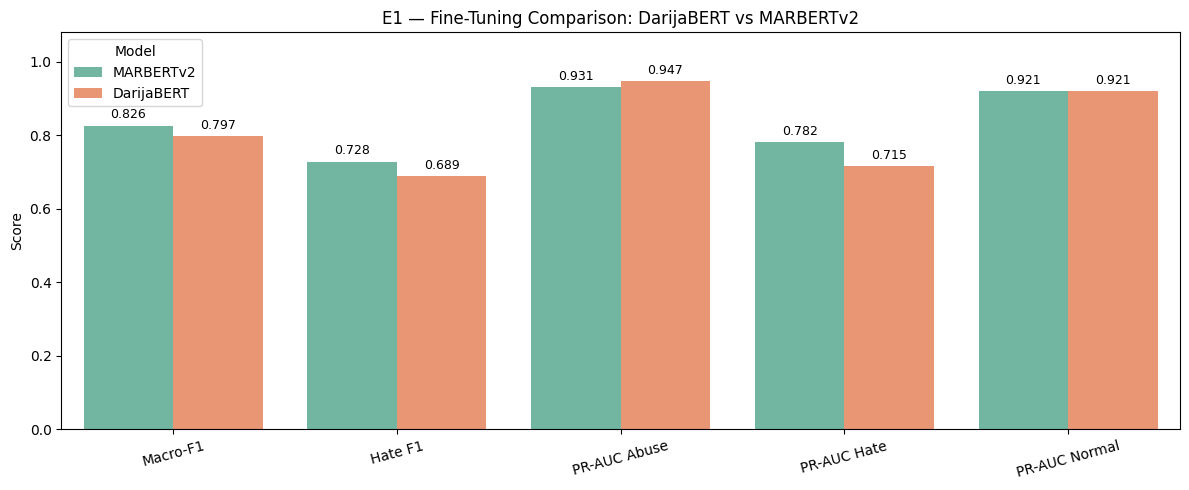

In [34]:

# ==========================================
# E1 — DARIJABERT VS MARBERTv2
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Résultats de E1
df_plot = comparison_E1.copy()

metrics = [
    "Macro-F1", "Hate F1",
    "PR-AUC Abuse", "PR-AUC Hate", "PR-AUC Normal"
]

# Format long pour Seaborn
df_long = df_plot.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 5))

ax = sns.barplot(
    data=df_long,
    x="Metric",
    y="Score",
    hue="Model",
    palette="Set2"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9)

plt.title("E1 — Fine-Tuning Comparison: DarijaBERT vs MARBERTv2")
plt.ylabel("Score")
plt.xlabel("")
plt.ylim(0, 1.08)
plt.xticks(rotation=15)
plt.legend(title="Model")
plt.tight_layout()
plt.show()


In [32]:

# =====================================================
# PART E2 — MULTI-TASK LEARNING
# Hate Speech Classification + Arabizi Detection
# =====================================================

import re
import gc
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from transformers import AutoTokenizer, AutoModel
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    f1_score, classification_report,
    precision_recall_curve, auc
)

# 1. Configuration
SEED = 42
MODEL_ID = "SI2M-Lab/DarijaBERT"
LAMBDAS = [0.0, 0.3, 0.5, 1.0]
EPOCHS = 2
BATCH_SIZE = 16
MAX_LEN = 128
LR = 2e-5

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASSES = ["Abuse", "Hate", "Normal"]
label2id = {c: i for i, c in enumerate(CLASSES)}

train_texts = df_train["tweet"].astype(str).tolist()
val_texts = df_val["tweet"].astype(str).tolist()

y_train = df_train["label"].map(label2id).to_numpy()
y_val = df_val["label"].map(label2id).to_numpy()

# 2. Arabizi detection (heuristic labels)
arabizi_words = {
    "wach", "3lach", "bzaf", "machi", "kifach",
    "bghit", "safi", "chno", "hadi", "hadchi",
    "nta", "nti", "khoya", "fin"
}

def detect_arabizi(text):
    text = str(text).lower()
    words = set(re.findall(r"[a-z0-9]+", text))

    has_arabizi_words = bool(words & arabizi_words)
    has_arabizi_digits = bool(
        re.search(r"[a-z]*[23789][a-z]+|[a-z]+[23789][a-z]*", text)
    )

    return int(has_arabizi_words or has_arabizi_digits)

aux_train = np.array([detect_arabizi(t) for t in train_texts])
aux_val = np.array([detect_arabizi(t) for t in val_texts])

print("Arabizi labels — Train:")
print(pd.Series(aux_train).value_counts())

# 3. Tokenization
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

def make_loader(texts, labels, aux_labels, shuffle=False):
    encoded = tokenizer(
        texts,
        padding="max_length",
        truncation=True,
        max_length=MAX_LEN,
        return_tensors="pt"
    )

    return DataLoader(
        TensorDataset(
            encoded["input_ids"],
            encoded["attention_mask"],
            torch.tensor(labels, dtype=torch.long),
            torch.tensor(aux_labels, dtype=torch.long)
        ),
        batch_size=BATCH_SIZE,
        shuffle=shuffle
    )

train_loader = make_loader(train_texts, y_train, aux_train, True)
val_loader = make_loader(val_texts, y_val, aux_val)

# 4. Multi-Task Architecture
class MultiTaskDarijaBERT(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = AutoModel.from_pretrained(MODEL_ID)
        hidden_size = self.encoder.config.hidden_size

        self.dropout = nn.Dropout(0.2)
        self.main_head = nn.Linear(hidden_size, 3)
        self.aux_head = nn.Linear(hidden_size, 2)

    def forward(self, input_ids, attention_mask):
        outputs = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        cls = self.dropout(outputs.last_hidden_state[:, 0, :])

        main_logits = self.main_head(cls)
        aux_logits = self.aux_head(cls)

        return main_logits, aux_logits

# 5. Evaluation function
def evaluate_model(model):
    model.eval()
    all_probs = []

    with torch.inference_mode():
        for ids, mask, _, _ in val_loader:
            main_logits, _ = model(
                ids.to(device),
                mask.to(device)
            )
            probs = torch.softmax(main_logits.float(), dim=1)
            all_probs.append(probs.cpu().numpy())

    return np.vstack(all_probs)

# 6. Class weights
counts = np.bincount(y_train, minlength=3)
weights = torch.tensor(
    len(y_train) / (3 * counts),
    dtype=torch.float32,
    device=device
)

main_criterion = nn.CrossEntropyLoss(weight=weights)
aux_criterion = nn.CrossEntropyLoss()

# 7. Training for each lambda
results_E2 = []

for lam in LAMBDAS:
    print(f"\n========== Lambda = {lam} ==========")

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model = MultiTaskDarijaBERT().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR)

    best_f1 = -1
    best_state = None

    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss = 0

        for ids, mask, y_main, y_aux in train_loader:
            ids = ids.to(device)
            mask = mask.to(device)
            y_main = y_main.to(device)
            y_aux = y_aux.to(device)

            optimizer.zero_grad()

            with torch.autocast(
                device_type="cuda",
                enabled=(device.type == "cuda")
            ):
                main_logits, aux_logits = model(ids, mask)

                loss_main = main_criterion(
                    main_logits.float(), y_main
                )
                loss_aux = aux_criterion(
                    aux_logits.float(), y_aux
                )

                loss = loss_main + lam * loss_aux

            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            total_loss += loss.item()

        probs = evaluate_model(model)
        preds = probs.argmax(axis=1)

        macro = f1_score(y_val, preds, average="macro")

        print(
            f"Epoch {epoch} | "
            f"Loss={total_loss / len(train_loader):.4f} | "
            f"Macro-F1={macro:.4f}"
        )

        if macro > best_f1:
            best_f1 = macro
            best_state = copy.deepcopy(model.state_dict())

    # Restore best checkpoint
    model.load_state_dict(best_state)
    probs = evaluate_model(model)
    preds = probs.argmax(axis=1)

    result = {
        "Lambda": lam,
        "Macro-F1": f1_score(
            y_val, preds, average="macro"
        ),
        "Hate F1": f1_score(
            y_val == 1, preds == 1, zero_division=0
        )
    }

    for i, label in enumerate(CLASSES):
        precision, recall, _ = precision_recall_curve(
            y_val == i, probs[:, i]
        )
        result[f"PR-AUC {label}"] = auc(recall, precision)

    results_E2.append(result)

    print("\nClassification Report:")
    print(classification_report(
        y_val, preds,
        target_names=CLASSES,
        zero_division=0
    ))

    # Save weights
    torch.save(
        model.state_dict(),
        f"/kaggle/working/E2_lambda_{lam}.pt"
    )

    pd.DataFrame(results_E2).to_csv(
        "/kaggle/working/results_E2.csv",
        index=False
    )

    del model, optimizer
    gc.collect()
    torch.cuda.empty_cache()

# 8. Final comparison
comparison_E2 = pd.DataFrame(results_E2).sort_values(
    "Macro-F1", ascending=False
).reset_index(drop=True)

print("\nE2 — MULTI-TASK COMPARISON")
display(comparison_E2.round(4))

print("\nBest Lambda:", comparison_E2.iloc[0]["Lambda"])
print("Best Macro-F1:", round(
    comparison_E2.iloc[0]["Macro-F1"], 4
))


Arabizi labels — Train:
0    2071
1    1169
Name: count, dtype: int64

========== Lambda = 0.0 ==========


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: SI2M-Lab/DarijaBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1 | Loss=0.7760 | Macro-F1=0.7237
Epoch 2 | Loss=0.4860 | Macro-F1=0.8036

Classification Report:
              precision    recall  f1-score   support

       Abuse       0.85      0.93      0.89       340
        Hate       0.68      0.74      0.71       102
      Normal       0.90      0.75      0.82       253

    accuracy                           0.84       695
   macro avg       0.81      0.80      0.80       695
weighted avg       0.84      0.84      0.83       695


========== Lambda = 0.3 ==========


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: SI2M-Lab/DarijaBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (5 outputs left out)

[transformers] BertModel LOAD REPORT from: SI2M-Lab/DarijaBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1 | Loss=1.1574 | Macro-F1=0.7069
Epoch 2 | Loss=0.6923 | Macro-F1=0.7780

Classification Report:
              precision    recall  f1-score   support

       Abuse       0.84      0.92      0.88       340
        Hate       0.62      0.74      0.68       102
      Normal       0.87      0.70      0.78       253

    accuracy                           0.81       695
   macro avg       0.78      0.79      0.78       695
weighted avg       0.82      0.81      0.81       695


E2 — MULTI-TASK COMPARISON


,Lambda,Macro-F1,Hate F1,PR-AUC Abuse,PR-AUC Hate,PR-AUC Normal
0,0.0,0.8036,0.7075,0.9327,0.7323,0.9139
1,0.3,0.7978,0.7097,0.9294,0.7234,0.9119
2,0.5,0.7951,0.7085,0.9298,0.7217,0.9061
3,1.0,0.7780,0.6757,0.9270,0.7018,0.8989



Best Lambda: 0.0
Best Macro-F1: 0.8036


**Multi-Task Performance Comparison**

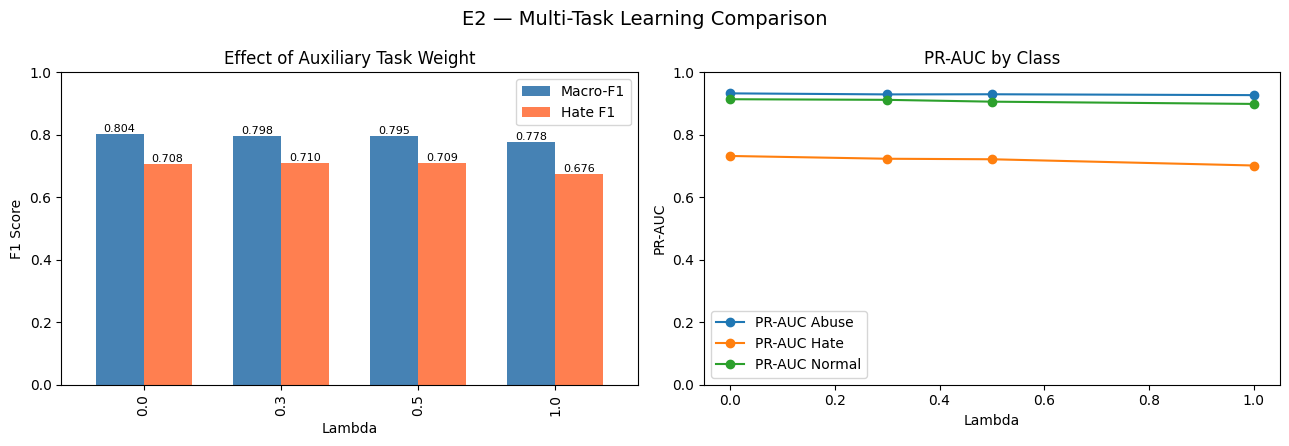

In [33]:

# ==========================================
# E2 — MULTI-TASK PERFORMANCE COMPARISON
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Results from E2
df_plot = comparison_E2.sort_values("Lambda").copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Macro-F1 & Hate F1
df_plot.plot(
    x="Lambda",
    y=["Macro-F1", "Hate F1"],
    kind="bar",
    ax=axes[0],
    color=["steelblue", "coral"],
    width=0.7
)

axes[0].set_title("Effect of Auxiliary Task Weight")
axes[0].set_xlabel("Lambda")
axes[0].set_ylabel("F1 Score")
axes[0].set_ylim(0, 1)
axes[0].legend(loc="upper right")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.3f", fontsize=8)

# 2. PR-AUC by Class
df_plot.plot(
    x="Lambda",
    y=["PR-AUC Abuse", "PR-AUC Hate", "PR-AUC Normal"],
    marker="o",
    ax=axes[1]
)

axes[1].set_title("PR-AUC by Class")
axes[1].set_xlabel("Lambda")
axes[1].set_ylabel("PR-AUC")
axes[1].set_ylim(0, 1)
axes[1].legend()

plt.suptitle("E2 — Multi-Task Learning Comparison", fontsize=14)
plt.tight_layout()
plt.show()



## Partie F — Robustesse, Ablations et Évaluation Finale

- **F1 :** Distribution des classes, ajustement du seuil sur Validation et évaluation finale sur Test.
- **F2 :** Évaluation Zero-Shot vs Fine-Tuning sur le dataset MAC.
- **F3 :** Analyse des performances selon le système d'écriture (Arabic, Latin, Mixed).
- **F4 :** Tests de robustesse et impact du prétraitement.
- **F5 :** Évaluation avec 3 graines aléatoires et intervalles de confiance.
- **F6 :** Analyse qualitative de 50 erreurs de classification.
- **Métriques :** Macro-F1, Hate F1 et PR-AUC par classe.


**Validation Threshold & Final Test**

LABEL DISTRIBUTION


,Validation (%),Test (%)
label,,
Abuse,48.92,48.93
Hate,14.68,14.59
Normal,36.40,36.48


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


BEST VALIDATION SETTING
Hate Bias    0.150000
Macro-F1     0.834984
Hate F1      0.747368

FINAL TEST RESULTS


,Model,Selected Hate Bias,Test Macro-F1,Test Hate F1,PR-AUC Abuse,PR-AUC Hate,PR-AUC Normal
0,MARBERTv2,0.15,0.7668,0.6354,0.9137,0.7046,0.9085


              precision    recall  f1-score   support

       Abuse       0.84      0.87      0.85       342
        Hate       0.68      0.60      0.64       102
      Normal       0.81      0.81      0.81       255

    accuracy                           0.81       699
   macro avg       0.78      0.76      0.77       699
weighted avg       0.81      0.81      0.81       699



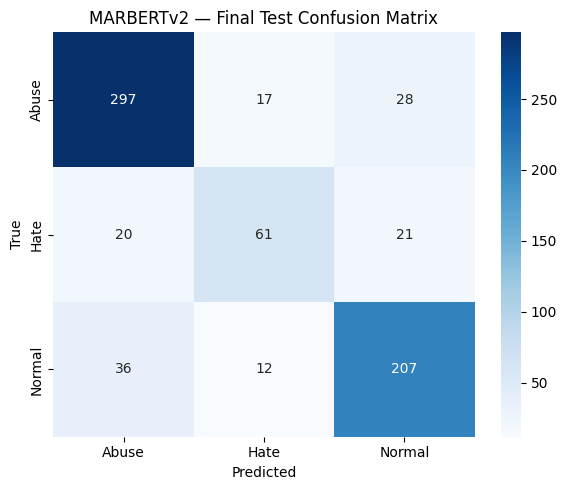

In [35]:

# =====================================================
# PART F1 — VALIDATION THRESHOLD & FINAL TEST
# =====================================================

import numpy as np
import pandas as pd
import torch

from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import (
    f1_score, classification_report,
    confusion_matrix, precision_recall_curve, auc
)
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import seaborn as sns

CLASSES = ["Abuse", "Hate", "Normal"]
MODEL_PATH = "/kaggle/working/E1_MARBERTv2_seed42"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Compare label distributions
distribution = pd.DataFrame({
    "Validation (%)": (
        df_val["label"].value_counts(normalize=True) * 100
    ),
    "Test (%)": (
        df_test["label"].value_counts(normalize=True) * 100
    )
}).reindex(CLASSES)

print("LABEL DISTRIBUTION")
display(distribution.round(2))

# 2. Load best fine-tuned model
tokenizer_F = AutoTokenizer.from_pretrained(MODEL_PATH)
model_F = AutoModelForSequenceClassification.from_pretrained(
    MODEL_PATH
).to(device)
model_F.eval()

def predict_probs_F(texts):
    encoded = tokenizer_F(
        list(texts),
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    )

    loader = DataLoader(
        TensorDataset(
            encoded["input_ids"],
            encoded["attention_mask"]
        ),
        batch_size=16
    )

    all_probs = []

    with torch.inference_mode():
        for ids, mask in loader:
            logits = model_F(
                input_ids=ids.to(device),
                attention_mask=mask.to(device)
            ).logits

            all_probs.append(
                torch.softmax(logits.float(), dim=1)
                .cpu().numpy()
            )

    probs = np.vstack(all_probs)

    # Align probabilities with our label order
    indices = [
        int(model_F.config.label2id[c])
        for c in CLASSES
    ]
    return probs[:, indices]

# 3. Validation predictions
val_probs = predict_probs_F(df_val["tweet"])
y_val_F = df_val["label"].to_numpy()

# Adjust Hate score only; other class scores unchanged
def predict_with_bias(probs, hate_bias):
    adjusted = probs.copy()
    adjusted[:, 1] += hate_bias
    return np.array(CLASSES)[adjusted.argmax(axis=1)]

# 4. Select bias using VALIDATION ONLY
threshold_results = []

for bias in np.arange(-0.30, 0.31, 0.025):
    predictions = predict_with_bias(val_probs, bias)

    threshold_results.append({
        "Hate Bias": round(float(bias), 3),
        "Macro-F1": f1_score(
            y_val_F, predictions, average="macro"
        ),
        "Hate F1": f1_score(
            y_val_F == "Hate",
            predictions == "Hate",
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
best = threshold_df.sort_values(
    ["Macro-F1", "Hate F1"],
    ascending=False
).iloc[0]

best_bias = float(best["Hate Bias"])

print("\nBEST VALIDATION SETTING")
print(best.to_string())

# 5. Apply selected bias to TEST (once)
test_probs = predict_probs_F(df_test["tweet"])
y_test_F = df_test["label"].to_numpy()
test_preds = predict_with_bias(test_probs, best_bias)

result_F1 = {
    "Model": "MARBERTv2",
    "Selected Hate Bias": best_bias,
    "Test Macro-F1": f1_score(
        y_test_F, test_preds, average="macro"
    ),
    "Test Hate F1": f1_score(
        y_test_F == "Hate",
        test_preds == "Hate",
        zero_division=0
    )
}

for i, label in enumerate(CLASSES):
    precision, recall, _ = precision_recall_curve(
        y_test_F == label, test_probs[:, i]
    )
    result_F1[f"PR-AUC {label}"] = auc(recall, precision)

print("\nFINAL TEST RESULTS")
display(pd.DataFrame([result_F1]).round(4))

print(classification_report(
    y_test_F, test_preds,
    labels=CLASSES, zero_division=0
))

# 6. Confusion matrix
cm = confusion_matrix(
    y_test_F, test_preds, labels=CLASSES
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASSES, yticklabels=CLASSES
)
plt.title("MARBERTv2 — Final Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

# 7. Save results
pd.DataFrame([result_F1]).to_csv(
    "/kaggle/working/results_F1.csv", index=False
)

pd.DataFrame({
    "tweet": df_test["tweet"].values,
    "true_label": y_test_F,
    "predicted_label": test_preds
}).to_csv(
    "/kaggle/working/F1_test_predictions.csv",
    index=False
)


**Généralisation à un dialecte non vu (Domain Shift)**

In [36]:

# =====================================================
# F2 — CROSS-DIALECT GENERALIZATION: ARY -> ARQ
# =====================================================

import gc
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import f1_score, classification_report, precision_recall_curve, auc
from torch.utils.data import DataLoader, TensorDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASSES = ["Abuse", "Hate", "Normal"]
label2id = {c: i for i, c in enumerate(CLASSES)}

MODEL_PATH = "/kaggle/working/E1_MARBERTv2_seed42"
MAX_LEN = 128
BATCH_SIZE = 8

# 1. Load Algerian Arabic dataset
dataset_arq = load_dataset("afrihate/afrihate", "arq")

df_arq_train = dataset_arq["train"].to_pandas()
df_arq_val = dataset_arq["validation"].to_pandas()
df_arq_test = dataset_arq["test"].to_pandas()

print("ARQ Train:", len(df_arq_train))
print("ARQ Validation:", len(df_arq_val))
print("ARQ Test:", len(df_arq_test))

# Check label compatibility
for df in [df_arq_train, df_arq_val, df_arq_test]:
    assert set(df["label"]).issubset(set(CLASSES)), "Unexpected labels in ARQ"

# 2. Load model trained on Moroccan Darija
tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_PATH
).to(device)

def make_loader(texts, labels, shuffle=False):
    enc = tokenizer(
        list(texts),
        padding="max_length",
        truncation=True,
        max_length=MAX_LEN,
        return_tensors="pt"
    )
    return DataLoader(
        TensorDataset(
            enc["input_ids"],
            enc["attention_mask"],
            torch.tensor(
                [label2id[y] for y in labels],
                dtype=torch.long
            )
        ),
        batch_size=BATCH_SIZE,
        shuffle=shuffle
    )

def evaluate(model, loader):
    model.eval()
    probs = []
    with torch.inference_mode():
        for ids, mask, _ in loader:
            with torch.autocast("cuda", enabled=device.type == "cuda"):
                logits = model(
                    input_ids=ids.to(device),
                    attention_mask=mask.to(device)
                ).logits
            probs.append(torch.softmax(logits.float(), dim=1).cpu().numpy())
    return np.vstack(probs)

def get_metrics(y_true, probs, name):
    y_true = np.array([label2id[y] for y in y_true])
    y_pred = probs.argmax(axis=1)

    row = {
        "Model": name,
        "Macro-F1": f1_score(y_true, y_pred, average="macro"),
        "Hate F1": f1_score(y_true == 1, y_pred == 1, zero_division=0)
    }

    for i, c in enumerate(CLASSES):
        p, r, _ = precision_recall_curve(y_true == i, probs[:, i])
        row[f"PR-AUC {c}"] = auc(r, p)

    return row

# 3. Zero adaptation: ARY model -> ARQ TEST
arq_test_loader = make_loader(df_arq_test["tweet"], df_arq_test["label"])
probs_before = evaluate(model, arq_test_loader)

results_F2 = [
    get_metrics(df_arq_test["label"], probs_before, "ARY -> ARQ (Before)")
]

print("\nBEFORE ADAPTATION")
display(pd.DataFrame(results_F2).round(4))

# 4. Fine-tune with ARY + ARQ training data
combined_train = pd.concat([
    df_train[["tweet", "label"]],
    df_arq_train[["tweet", "label"]]
], ignore_index=True)

train_loader = make_loader(
    combined_train["tweet"],
    combined_train["label"],
    shuffle=True
)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-5)

counts = np.bincount(
    [label2id[y] for y in combined_train["label"]],
    minlength=3
)
weights = torch.tensor(
    len(combined_train) / (3 * counts),
    dtype=torch.float32,
    device=device
)
criterion = torch.nn.CrossEntropyLoss(weight=weights)
scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")

# ARY + ARQ validation for checkpoint selection
combined_val = pd.concat([
    df_val[["tweet", "label"]],
    df_arq_val[["tweet", "label"]]
], ignore_index=True)

val_loader = make_loader(combined_val["tweet"], combined_val["label"])

best_score = -1
best_state = None

for epoch in range(1, 3):
    model.train()
    losses = []

    for ids, mask, targets in train_loader:
        ids = ids.to(device)
        mask = mask.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        with torch.autocast("cuda", enabled=device.type == "cuda"):
            logits = model(
                input_ids=ids,
                attention_mask=mask
            ).logits
            loss = criterion(logits.float(), targets)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()

        losses.append(loss.item())

    val_probs = evaluate(model, val_loader)
    val_true = np.array([label2id[y] for y in combined_val["label"]])
    score = f1_score(val_true, val_probs.argmax(axis=1), average="macro")

    print(f"Epoch {epoch} | Loss={np.mean(losses):.4f} | Val Macro-F1={score:.4f}")

    if score > best_score:
        best_score = score
        model.save_pretrained("/kaggle/working/F2_MARBERTv2_ARY_ARQ")
        tokenizer.save_pretrained("/kaggle/working/F2_MARBERTv2_ARY_ARQ")

# 5. Evaluate adapted model on ARQ TEST
del model
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSequenceClassification.from_pretrained(
    "/kaggle/working/F2_MARBERTv2_ARY_ARQ"
).to(device)

probs_after = evaluate(model, arq_test_loader)

results_F2.append(
    get_metrics(df_arq_test["label"], probs_after, "ARY + ARQ (After)")
)

# 6. Comparison
comparison_F2 = pd.DataFrame(results_F2)

print("\nF2 — CROSS-DIALECT COMPARISON")
display(comparison_F2.round(4))

comparison_F2.to_csv("/kaggle/working/results_F2.csv", index=False)


train.tsv:   0%|          | 0.00/153k [00:00<?, ?B/s]

dev.tsv:   0%|          | 0.00/43.5k [00:00<?, ?B/s]

test.tsv:   0%|          | 0.00/78.4k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

... (6 outputs left out)

Epoch 2 | Loss=0.2421 | Val Macro-F1=0.7990


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


F2 — CROSS-DIALECT COMPARISON


,Model,Macro-F1,Hate F1,PR-AUC Abuse,PR-AUC Hate,PR-AUC Normal
0,ARY -> ARQ (Before),0.6197,0.5083,0.7864,0.5338,0.6803
1,ARY + ARQ (After),0.6632,0.5375,0.8649,0.6427,0.7364


**Performance by Writing Script**

F3 — PERFORMANCE BY SCRIPT


,Script,Tweets,Macro-F1,Hate F1,Hate Support
0,Arabic,237,0.7643,0.5846,36
2,Mixed,244,0.7630,0.6329,40
1,Latin,217,0.6606,0.7083,26
3,Other,1,0.3333,0.0000,0


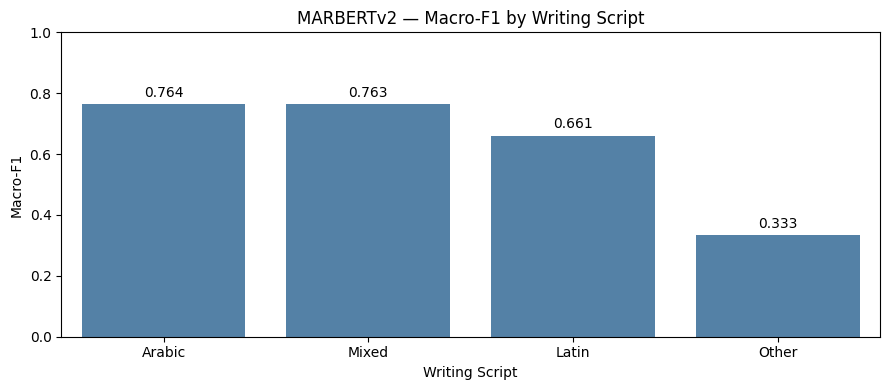


CLASS DISTRIBUTION BY SCRIPT — TEST


label,Abuse,Hate,Normal
script,,,
Arabic,118,36,83
Latin,152,26,39
Mixed,72,40,132
Other,0,0,1


In [37]:

# =====================================================
# F3 — PERFORMANCE BY WRITING SCRIPT
# =====================================================

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    f1_score, classification_report,
    confusion_matrix
)

# 1. Detect script from original tweets
# Remove URLs and mentions to avoid false "Mixed" labels

def detect_script_f3(text):
    text = str(text)
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'@\w+', ' ', text)

    arabic = bool(re.search(r'[\u0600-\u06FF]', text))
    latin = bool(re.search(r'[a-zA-Z]', text))

    if arabic and latin:
        return "Mixed"
    elif arabic:
        return "Arabic"
    elif latin:
        return "Latin"
    return "Other"

# 2. Apply on TEST
df_f3 = df_test[["tweet", "label"]].copy()

df_f3["script"] = df_f3["tweet"].apply(detect_script_f3)

# Reuse final predictions from F1
df_f3["prediction"] = test_preds

# 3. Calculate metrics for each script
results_F3 = []

for script, group in df_f3.groupby("script"):

    macro = f1_score(
        group["label"],
        group["prediction"],
        labels=["Abuse", "Hate", "Normal"],
        average="macro",
        zero_division=0
    )

    hate = f1_score(
        group["label"] == "Hate",
        group["prediction"] == "Hate",
        zero_division=0
    )

    results_F3.append({
        "Script": script,
        "Tweets": len(group),
        "Macro-F1": macro,
        "Hate F1": hate,
        "Hate Support": (group["label"] == "Hate").sum()
    })

comparison_F3 = pd.DataFrame(results_F3).sort_values(
    "Macro-F1", ascending=False
)

print("F3 — PERFORMANCE BY SCRIPT")
display(comparison_F3.round(4))

# 4. Visualization
plt.figure(figsize=(9, 4))

ax = sns.barplot(
    data=comparison_F3,
    x="Script",
    y="Macro-F1",
    color="steelblue"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.title("MARBERTv2 — Macro-F1 by Writing Script")
plt.ylabel("Macro-F1")
plt.xlabel("Writing Script")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# 5. Class distribution by script
print("\nCLASS DISTRIBUTION BY SCRIPT — TEST")

display(pd.crosstab(
    df_f3["script"],
    df_f3["label"]
))

# 6. Save
comparison_F3.to_csv(
    "/kaggle/working/results_F3.csv",
    index=False
)



### F4 — Robustness & Text Ablation

- Évaluer la robustesse de MARBERTv2 face aux modifications des tweets.
- Supprimer les emojis, la ponctuation répétée et les mots injurieux.
- Comparer les performances avant et après chaque modification.
- Mesurer l'impact sur le Macro-F1 et le Hate F1.
- Identifier les éléments textuels influençant les prédictions.


Correctly classified Hate/Abuse: 358

F4 — ROBUSTNESS COMPARISON


,Transformation,Modified Tweets,Macro-F1,Hate F1,Correct Retained (%),Macro-F1 Change
0,Original,0,0.7668,0.6354,100.0000,0.0000
1,No Emojis,58,0.7703,0.6421,100.0000,0.0036
2,No Repeated Punctuation,57,0.7668,0.6354,100.0000,0.0000
3,No Insults,304,0.7599,0.6321,97.7654,-0.0068
4,All Removed,360,0.7624,0.6387,97.4860,-0.0044


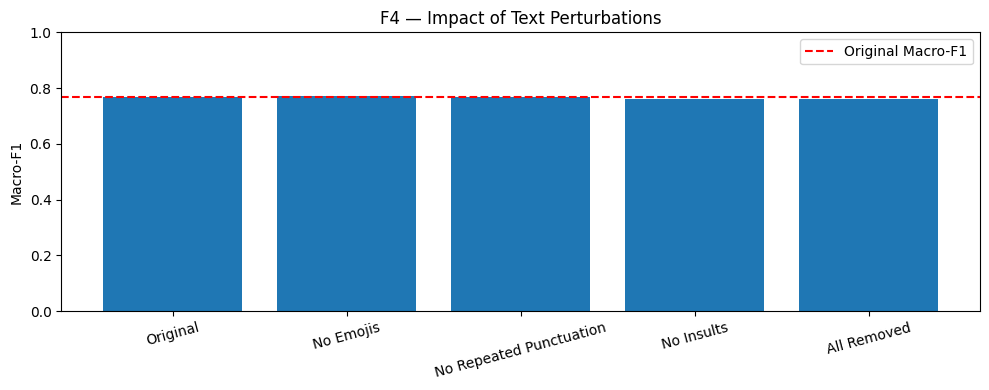

In [38]:

# =====================================================
# F4 — ROBUSTNESS & TEXT ABLATION
# =====================================================

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

# 1. Text perturbations
def remove_emojis(text):
    return re.sub(
        r'[\U0001F300-\U0001FAFF\u2600-\u27BF]',
        '', str(text)
    )

def remove_repeated_punctuation(text):
    return re.sub(r'([!?.,;:])\1+', r'\1', str(text))

def remove_insults(text):
    words = set(insult_lexicon)
    tokens = str(text).split()
    return ' '.join(
        token for token in tokens
        if re.sub(r'^\W+|\W+$', '', token) not in words
    )

def remove_all(text):
    return remove_insults(
        remove_repeated_punctuation(
            remove_emojis(text)
        )
    )

transformations = {
    "Original": lambda x: x,
    "No Emojis": remove_emojis,
    "No Repeated Punctuation": remove_repeated_punctuation,
    "No Insults": remove_insults,
    "All Removed": remove_all
}

# 2. Select correctly classified Hate/Abuse tweets
original_true = df_test["label"].to_numpy()
original_preds = np.array(test_preds)
texts = df_test["tweet"].astype(str).tolist()

selected_mask = (
    np.isin(original_true, ["Hate", "Abuse"])
    & (original_true == original_preds)
)

print("Correctly classified Hate/Abuse:",
      selected_mask.sum())

# 3. Evaluate perturbations on the full test set
results_F4 = []

for name, transform in transformations.items():

    modified_texts = [transform(t) for t in texts]

    if name == "Original":
        pred = original_preds.copy()
    else:
        probs = predict_probs_F(modified_texts)
        pred = predict_with_bias(probs, best_bias)

    changed = np.array([
        a != b for a, b in zip(texts, modified_texts)
    ])

    # Among initially correct Hate/Abuse examples,
    # what percentage remains correctly classified?
    retained = (
        (pred[selected_mask] == original_true[selected_mask])
        .mean()
        if selected_mask.sum() else np.nan
    )

    row = {
        "Transformation": name,
        "Modified Tweets": int(changed.sum()),
        "Macro-F1": f1_score(
            original_true, pred, average="macro"
        ),
        "Hate F1": f1_score(
            original_true == "Hate",
            pred == "Hate",
            zero_division=0
        ),
        "Correct Retained (%)": retained * 100
    }

    results_F4.append(row)

# 4. Comparison
comparison_F4 = pd.DataFrame(results_F4)

baseline_f1 = comparison_F4.iloc[0]["Macro-F1"]
comparison_F4["Macro-F1 Change"] = (
    comparison_F4["Macro-F1"] - baseline_f1
)

print("\nF4 — ROBUSTNESS COMPARISON")
display(comparison_F4.round(4))

# 5. Visualization
plt.figure(figsize=(10, 4))
plt.bar(
    comparison_F4["Transformation"],
    comparison_F4["Macro-F1"]
)
plt.axhline(
    baseline_f1,
    linestyle="--",
    color="red",
    label="Original Macro-F1"
)
plt.title("F4 — Impact of Text Perturbations")
plt.ylabel("Macro-F1")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend()
plt.tight_layout()
plt.show()

# 6. Save results
comparison_F4.to_csv(
    "/kaggle/working/results_F4.csv",
    index=False
)



### F5 — Bootstrap Confidence Intervals

- Évaluer la fiabilité des performances de MARBERTv2 sur Test.
- Générer 1 000 échantillons Bootstrap avec remise.
- Calculer les intervalles de confiance à 95 % du Macro-F1 et du Hate F1.
- Visualiser la distribution des scores.
- Mesurer l'incertitude des performances sans réentraîner le modèle.


F5 — BOOTSTRAP 95% CONFIDENCE INTERVALS


,Metric,Score,CI Lower,CI Upper
0,Macro-F1,0.7668,0.7277,0.8001
1,Hate F1,0.6354,0.5497,0.7059


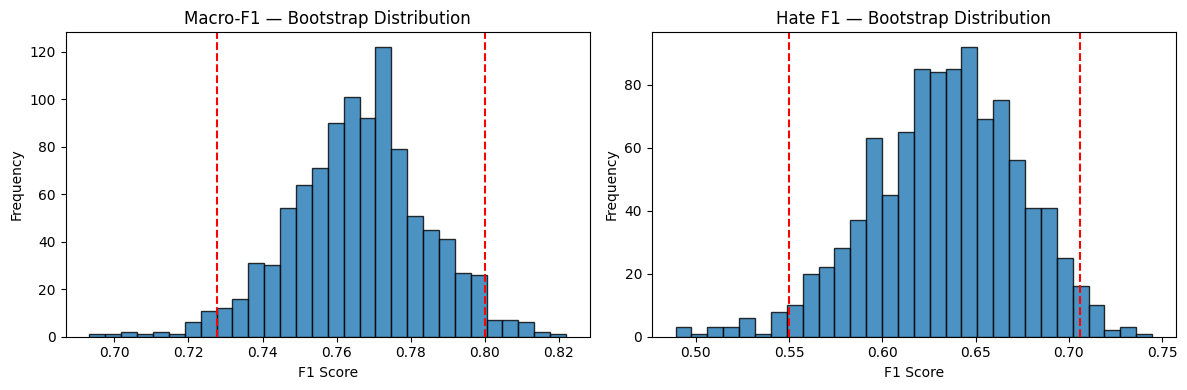

In [39]:

# =====================================================
# F5 — BOOTSTRAP CONFIDENCE INTERVALS
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

SEED = 42
N_BOOTSTRAP = 1000
rng = np.random.default_rng(SEED)

# Predictions from F1 — MARBERTv2 on TEST
y_true = np.array(y_test_F)
y_pred = np.array(test_preds)

# 1. Bootstrap sampling
bootstrap_macro = []
bootstrap_hate = []

for _ in range(N_BOOTSTRAP):

    indices = rng.choice(
        len(y_true),
        size=len(y_true),
        replace=True
    )

    yt = y_true[indices]
    yp = y_pred[indices]

    bootstrap_macro.append(
        f1_score(
            yt, yp,
            labels=["Abuse", "Hate", "Normal"],
            average="macro",
            zero_division=0
        )
    )

    bootstrap_hate.append(
        f1_score(
            yt == "Hate",
            yp == "Hate",
            zero_division=0
        )
    )

# 2. Confidence intervals
def bootstrap_ci(scores):
    return np.percentile(scores, [2.5, 97.5])

macro_ci = bootstrap_ci(bootstrap_macro)
hate_ci = bootstrap_ci(bootstrap_hate)

macro_f1 = f1_score(
    y_true, y_pred, average="macro"
)

hate_f1 = f1_score(
    y_true == "Hate", y_pred == "Hate"
)

results_F5 = pd.DataFrame([
    {
        "Metric": "Macro-F1",
        "Score": macro_f1,
        "CI Lower": macro_ci[0],
        "CI Upper": macro_ci[1]
    },
    {
        "Metric": "Hate F1",
        "Score": hate_f1,
        "CI Lower": hate_ci[0],
        "CI Upper": hate_ci[1]
    }
])

print("F5 — BOOTSTRAP 95% CONFIDENCE INTERVALS")
display(results_F5.round(4))

# 3. Visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, scores, title, ci in zip(
    axes,
    [bootstrap_macro, bootstrap_hate],
    ["Macro-F1", "Hate F1"],
    [macro_ci, hate_ci]
):
    ax.hist(scores, bins=30, edgecolor="black", alpha=0.8)
    ax.axvline(ci[0], linestyle="--", color="red")
    ax.axvline(ci[1], linestyle="--", color="red")
    ax.set_title(f"{title} — Bootstrap Distribution")
    ax.set_xlabel("F1 Score")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

# 4. Save
results_F5.to_csv(
    "/kaggle/working/results_F5_bootstrap.csv",
    index=False
)


# McNemar Statistical Test MARBERTv2 vs Linear SVM

In [53]:

# =====================================================
# F5 — McNEMAR TEST: MARBERTv2 VS LINEAR SVM
# =====================================================

import numpy as np
import pandas as pd
from scipy.stats import binomtest
from sklearn.metrics import f1_score, confusion_matrix

# 1. Ground-truth test labels
y_true = df_test["label"].to_numpy()

# 2. MARBERTv2 predictions from F1
pred_marbert = np.asarray(test_preds)

# 3. Linear SVM predictions on the same TEST set
svm_model = trained_models_A["Linear SVM"]

pred_svm = svm_model.predict(df_test["clean_tweet"])

# 4. Model scores
comparison = pd.DataFrame([
    {
        "Model": "MARBERTv2",
        "Macro-F1": f1_score(
            y_true, pred_marbert, average="macro"
        ),
        "Hate F1": f1_score(
            y_true == "Hate", pred_marbert == "Hate"
        )
    },
    {
        "Model": "Linear SVM",
        "Macro-F1": f1_score(
            y_true, pred_svm, average="macro"
        ),
        "Hate F1": f1_score(
            y_true == "Hate", pred_svm == "Hate"
        )
    }
])

print("TEST COMPARISON")
display(comparison.round(4))

# 5. Paired correctness
marbert_correct = pred_marbert == y_true
svm_correct = pred_svm == y_true

both_correct = np.sum(marbert_correct & svm_correct)
marbert_only = np.sum(marbert_correct & ~svm_correct)
svm_only = np.sum(~marbert_correct & svm_correct)
both_wrong = np.sum(~marbert_correct & ~svm_correct)

contingency = pd.DataFrame(
    [
        [both_correct, marbert_only],
        [svm_only, both_wrong]
    ],
    index=["MARBERT Correct", "MARBERT Wrong"],
    columns=["SVM Correct", "SVM Wrong"]
)

print("\nMcNEMAR CONTINGENCY TABLE")
display(contingency)

# 6. Exact McNemar test
discordant = marbert_only + svm_only

if discordant > 0:
    p_value = binomtest(
        min(marbert_only, svm_only),
        n=discordant,
        p=0.5,
        alternative="two-sided"
    ).pvalue
else:
    p_value = 1.0

print("\nExact McNemar p-value:", round(p_value, 6))

if p_value < 0.05:
    print("Statistically significant difference (p < 0.05)")
else:
    print("No statistically significant difference (p >= 0.05)")

# 7. Save
comparison.to_csv(
    "/kaggle/working/F5_McNemar_comparison.csv",
    index=False
)


TEST COMPARISON


,Model,Macro-F1,Hate F1
0,MARBERTv2,0.7668,0.6354
1,Linear SVM,0.7620,0.6082



McNEMAR CONTINGENCY TABLE


,SVM Correct,SVM Wrong
MARBERT Correct,517,48
MARBERT Wrong,50,84



Exact McNemar p-value: 0.919607
No statistically significant difference (p >= 0.05)



### F6 — Qualitative Error Analysis

- Identifier les tweets mal classifiés par MARBERTv2.
- Sélectionner 50 erreurs représentatives des différents types de confusion.
- Analyser les difficultés linguistiques : Arabizi, code-switching, ambiguïté et contexte.
- Étudier les confusions Hate / Abuse / Normal.
- Identifier les limites du modèle et proposer des améliorations.


Total errors: 134

ERROR DISTRIBUTION
Error Type
Normal → Abuse    36
Abuse → Normal    28
Hate → Normal     21
Hate → Abuse      20
Abuse → Hate      17
Normal → Hate     12
Name: count, dtype: int64

50 SELECTED ERRORS


,tweet,label,prediction,Error Type,Script,Error Cause,Notes
0,جيت لايموزار مافيها والو بسيف بوز فلو ميولي ملحد,Abuse,Hate,Abuse → Hate,Arabic,,
1,ImeneYNadaMas يمكن مع كونتي بين شويا فهاد 352 ...,Abuse,Normal,Abuse → Normal,Mixed,,
2,داك بوصوفة شحال قصيور,Hate,Abuse,Hate → Abuse,Arabic,,
3,@username الجميعة العربية ماتت مند رحيل الزعما...,Hate,Normal,Hate → Normal,Mixed,,
4,GanaElisssa في بقرة دخلت السجن ليششافوها تاكل ...,Normal,Abuse,Normal → Abuse,Mixed,,
5,3wazza lbaggy tay7 hta f koora respect Brother...,Normal,Hate,Normal → Hate,Latin,,
6,@basmaTAM661 @hayettlena \nيا حمارة كاين سعودي...,Abuse,Hate,Abuse → Hate,Arabic,,
7,StaracArabia wa baaaaaaaaaaaaaaaaaaaz lwjohkom...,Abuse,Normal,Abuse → Normal,Latin,,
8,sweety_anosh BelkacemMorsli \nهاد الكلب حنان ب...,Hate,Abuse,Hate → Abuse,Mixed,,
9,@username لي ما حداهش غليظة حياتو مريضة، گالته...,Hate,Normal,Hate → Normal,Arabic,,


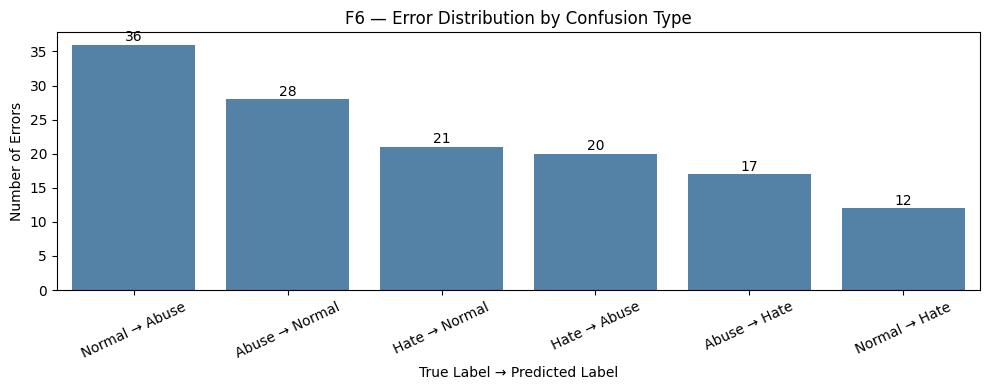


Saved: F6_50_errors.csv


In [40]:

# =====================================================
# PART F6 — ERROR ANALYSIS (50 MISCLASSIFIED TWEETS)
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

CLASSES = ["Abuse", "Hate", "Normal"]
SEED = 42

# 1. Test predictions from F1
errors_df = df_test[["id", "tweet", "label"]].copy()
errors_df["prediction"] = np.array(test_preds)

# 2. Select misclassified tweets
errors = errors_df[
    errors_df["label"] != errors_df["prediction"]
].copy()

errors["Error Type"] = (
    errors["label"] + " → " + errors["prediction"]
)

print("Total errors:", len(errors))
print("\nERROR DISTRIBUTION")
print(errors["Error Type"].value_counts())

# 3. Sample up to 50 errors across error types
rng = np.random.default_rng(SEED)
groups = [
    group.index.to_numpy()
    for _, group in errors.groupby("Error Type")
]

selected_indices = []
target = min(50, len(errors))

# Round-robin sampling across error categories
for group in groups:
    rng.shuffle(group)

while len(selected_indices) < target:
    added = False

    for group in groups:
        if len(selected_indices) >= target:
            break

        available = [
            i for i in group
            if i not in selected_indices
        ]

        if available:
            selected_indices.append(available[0])
            added = True

    if not added:
        break

sample_errors = errors.loc[selected_indices].copy()

# 4. Linguistic features
def detect_error_features(text):
    import re
    text = str(text)
    text_clean = re.sub(
        r'https?://\S+|@\w+', '', text
    )

    has_arabic = bool(re.search(r'[\u0600-\u06FF]', text_clean))
    has_latin = bool(re.search(r'[a-zA-Z]', text_clean))

    if has_arabic and has_latin:
        return "Mixed"
    if has_arabic:
        return "Arabic"
    if has_latin:
        return "Latin"
    return "Other"

sample_errors["Script"] = sample_errors["tweet"].apply(
    detect_error_features
)

# 5. Manual annotation template
sample_errors["Error Cause"] = ""
sample_errors["Notes"] = ""

# 6. Display sample
print("\n50 SELECTED ERRORS")
display(sample_errors[
    ["tweet", "label", "prediction",
     "Error Type", "Script", "Error Cause", "Notes"]
].reset_index(drop=True))

# 7. Confusion types
plt.figure(figsize=(10, 4))

counts = errors["Error Type"].value_counts()

ax = sns.barplot(
    x=counts.index,
    y=counts.values,
    color="steelblue"
)

for i, value in enumerate(counts.values):
    ax.text(i, value + 0.5, str(value), ha="center")

plt.title("F6 — Error Distribution by Confusion Type")
plt.xlabel("True Label → Predicted Label")
plt.ylabel("Number of Errors")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# 8. Save CSV for manual analysis
sample_errors.to_csv(
    "/kaggle/working/F6_50_errors.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nSaved: F6_50_errors.csv")


**Error Annotation Preparation**

In [44]:

# ==================================================
# F6 — MANUAL ERROR ANNOTATION
# ==================================================

import pandas as pd

# Reprendre les 50 erreurs déjà sélectionnées
annotation_df = sample_errors.copy().reset_index(drop=True)

# Catégories possibles
error_categories = [
    "Class Overlap",
    "Arabizi / Orthographic Variation",
    "Code-Switching",
    "Context Ambiguity",
    "Sarcasm / Irony",
    "Implicit Hate Speech",
    "Possible Label Noise",
    "Other"
]

# Colonnes pour l'analyse manuelle
annotation_df["Error Cause"] = ""
annotation_df["Explanation"] = ""

annotation_df.insert(
    0, "Error ID",
    range(1, len(annotation_df) + 1)
)

print("Total errors to annotate:", len(annotation_df))

print("\nPossible annotation categories:")
for category in error_categories:
    print("-", category)

display(annotation_df[
    [
        "Error ID",
        "tweet",
        "label",
        "prediction",
        "Script",
        "Error Cause",
        "Explanation"
    ]
])

# Export annotation template
annotation_df.to_csv(
    "/kaggle/working/F6_manual_annotations.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nAnnotation template saved successfully!")


Total errors to annotate: 50

Possible annotation categories:
- Class Overlap
- Arabizi / Orthographic Variation
- Code-Switching
- Context Ambiguity
- Sarcasm / Irony
- Implicit Hate Speech
- Possible Label Noise
- Other


,Error ID,tweet,label,prediction,Script,Error Cause,Explanation
0,1,جيت لايموزار مافيها والو بسيف بوز فلو ميولي ملحد,Abuse,Hate,Arabic,,
1,2,ImeneYNadaMas يمكن مع كونتي بين شويا فهاد 352 ...,Abuse,Normal,Mixed,,
2,3,داك بوصوفة شحال قصيور,Hate,Abuse,Arabic,,
3,4,@username الجميعة العربية ماتت مند رحيل الزعما...,Hate,Normal,Mixed,,
4,5,GanaElisssa في بقرة دخلت السجن ليششافوها تاكل ...,Normal,Abuse,Mixed,,
5,6,3wazza lbaggy tay7 hta f koora respect Brother...,Normal,Hate,Latin,,
6,7,@basmaTAM661 @hayettlena \nيا حمارة كاين سعودي...,Abuse,Hate,Arabic,,
7,8,StaracArabia wa baaaaaaaaaaaaaaaaaaaz lwjohkom...,Abuse,Normal,Latin,,
8,9,sweety_anosh BelkacemMorsli \nهاد الكلب حنان ب...,Hate,Abuse,Mixed,,
9,10,@username لي ما حداهش غليظة حياتو مريضة، گالته...,Hate,Normal,Arabic,,



Annotation template saved successfully!


In [45]:

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 60)

display(
    annotation_df[
        ["Error ID", "tweet", "label", "prediction", "Script"]
    ]
)


,Error ID,tweet,label,prediction,Script
0,1,جيت لايموزار مافيها والو بسيف بوز فلو ميولي ملحد,Abuse,Hate,Arabic
1,2,ImeneYNadaMas يمكن مع كونتي بين شويا فهاد 352 مي باش كان 3 كان معوق,Abuse,Normal,Mixed
2,3,داك بوصوفة شحال قصيور,Hate,Abuse,Arabic
3,4,@username الجميعة العربية ماتت مند رحيل الزعماء3 ملك المغرب الحسن الثاني وملك الاردون الحسين وملك السعودية عبد الله طيب الله تراهما واسكنهم في جناته إما الآن الجميعة العربية يكتبها بولغيط للجزائر في سميتها الماء وشطابة حتى القاع البحر لوكان الخوخ يداوي يداوى راسوا ##url,Hate,Normal,Mixed
4,5,GanaElisssa في بقرة دخلت السجن ليششافوها تاكل حشيش hhhhhhhhh,Normal,Abuse,Mixed
5,6,3wazza lbaggy tay7 hta f koora respect Brotherhood,Normal,Hate,Latin
6,7,@basmaTAM661 @hayettlena \nيا حمارة كاين سعودي يدافع عليك ونتي تقولي عليهم ال سلول يهود 😂😂 لهذا السبب دخلو لك الخليجيين حتى جرتلوك ومارضيتيش,Abuse,Hate,Arabic
7,8,StaracArabia wa baaaaaaaaaaaaaaaaaaaz lwjohkom makat7chmoch abdo w rayan w charfa mkhalinha wa khlouha tatwa7d mayb9a ytfarj fikom,Abuse,Normal,Latin
8,9,sweety_anosh BelkacemMorsli \nهاد الكلب حنان براسها سبها عندي فالمنشن وسوها واحق الله\nودابا كيتمسكن ناااري يهودي صافي هههه\nStaracArabia,Hate,Abuse,Mixed
9,10,@username لي ما حداهش غليظة حياتو مريضة، گالتها خديجة مرگوم,Hate,Normal,Arabic


# **Ajouter les annotations**

In [46]:

import pandas as pd
import glob

# Find uploaded annotation file
files = glob.glob(
    "/kaggle/input/**/F6_annotations_preliminaires_49.csv",
    recursive=True
)

print("Found:", files)

annotations = pd.read_csv(files[0])

print("Total annotations:", len(annotations))
print("Columns:", annotations.columns.tolist())

display(annotations.head(10))


Found: ['/kaggle/input/datasets/oumaymazerrik/qualitative-error-analysis-and-manual-annotation/F6_annotations_preliminaires_49.csv']
Total annotations: 49
Columns: ['Error ID', 'tweet', 'label', 'prediction', 'Script', 'Error Cause', 'Explanation', 'Review Status']


,Error ID,tweet,label,prediction,Script,Error Cause,Explanation,Review Status
0,1,جيت لايموزار مافيها والو بسيف بوز فلو ميولي ملحد,Abuse,Hate,Arabic,Context Ambiguity,Référence à la religion/athéisme; cible et intention injurieuse peu claires.,À vérifier manuellement
1,2,ImeneYNadaMas يمكن مع كونتي بين شويا فهاد 352 مي باش كان 3 كان معوق,Abuse,Normal,Mixed,Arabizi / Orthographic Variation,Transcription mixte et chiffres rendent le sens de l’insulte difficile à lire.,À vérifier manuellement
2,3,داك بوصوفة شحال قصيور,Hate,Abuse,Arabic,Possible Label Noise,Moquerie individuelle sur la taille; le label Hate mérite vérification.,À vérifier manuellement
3,4,@username الجميعة العربية ماتت مند رحيل الزعماء3 ملك المغرب الحسن الثاني وملك الاردون الحسين وملك السعودية عبد الله طيب الله تراهما واسكنهم في جناته إما الآن الجميعة العربية يكتبها بولغيط للجزائر في سميتها الماء وشطابة حتى القاع البحر لوكان الخوخ يداوي يداوى راسوا ##url,Hate,Normal,Mixed,Context Ambiguity,Long commentaire politique et allusions; cible haineuse difficile à établir.,À vérifier manuellement
4,5,GanaElisssa في بقرة دخلت السجن ليششافوها تاكل حشيش hhhhhhhhh,Normal,Abuse,Mixed,Sarcasm / Irony,Blague sur une vache; langage familier susceptible d’être pris pour une injure.,À vérifier manuellement
5,6,3wazza lbaggy tay7 hta f koora respect Brotherhood,Normal,Hate,Latin,Arabizi / Orthographic Variation,Darija latine et langage sportif; sens de 3wazza et du propos à confirmer.,À vérifier manuellement
6,7,@basmaTAM661 @hayettlena \nيا حمارة كاين سعودي يدافع عليك ونتي تقولي عليهم ال سلول يهود 😂😂 لهذا السبب دخلو لك الخليجيين حتى جرتلوك ومارضيتيش,Abuse,Hate,Arabic,Class Overlap,Insulte personnelle et référence à des groupes religieux/nationaux.,À vérifier manuellement
7,8,StaracArabia wa baaaaaaaaaaaaaaaaaaaz lwjohkom makat7chmoch abdo w rayan w charfa mkhalinha wa khlouha tatwa7d mayb9a ytfarj fikom,Abuse,Normal,Latin,Arabizi / Orthographic Variation,Reproches écrits en Arabizi avec longues répétitions de lettres.,À vérifier manuellement
8,9,sweety_anosh BelkacemMorsli \nهاد الكلب حنان براسها سبها عندي فالمنشن وسوها واحق الله\nودابا كيتمسكن ناااري يهودي صافي هههه\nStaracArabia,Hate,Abuse,Mixed,Context Ambiguity,Insultes et terme religieux cités dans une discussion; cible de haine ambiguë.,À vérifier manuellement
9,10,@username لي ما حداهش غليظة حياتو مريضة، گالتها خديجة مرگوم,Hate,Normal,Arabic,Context Ambiguity,"Proverbe/citation indirecte, sans cible explicite.",À vérifier manuellement


# Error Causes Distribution

ERROR CAUSES SUMMARY


,Number of Errors
Error Cause,
Context Ambiguity,16
Class Overlap,11
Arabizi / Orthographic Variation,9
Possible Label Noise,6
Implicit Hate Speech,4
Code-Switching,2
Sarcasm / Irony,1


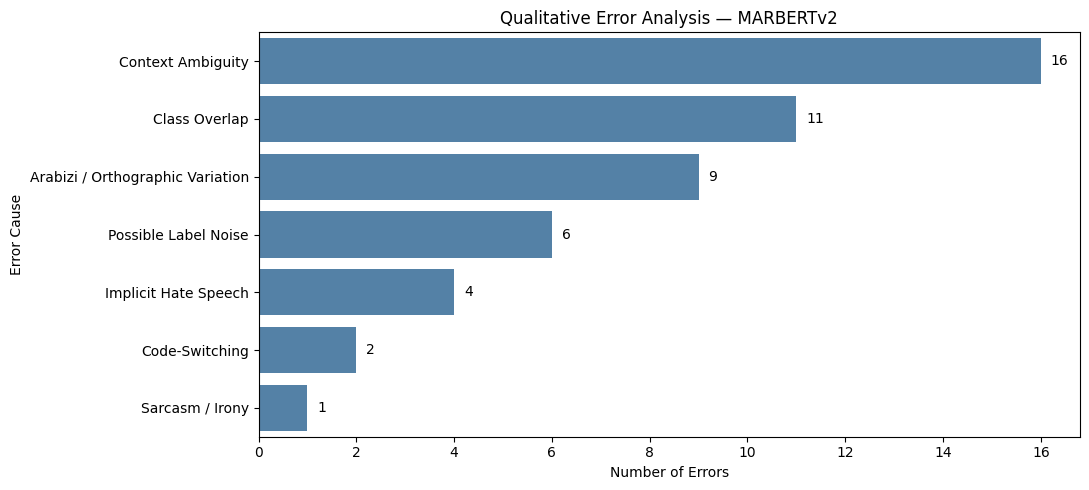

In [47]:

# ==========================================
# F6 — ERROR CAUSES DISTRIBUTION
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

# Distribution des causes annotées
counts = annotations["Error Cause"].value_counts()

print("ERROR CAUSES SUMMARY")
display(counts.to_frame("Number of Errors"))

# Visualisation
plt.figure(figsize=(11, 5))

ax = sns.barplot(
    x=counts.values,
    y=counts.index,
    color="steelblue"
)

for i, value in enumerate(counts.values):
    ax.text(value + 0.2, i, str(value), va="center")

plt.title("Qualitative Error Analysis — MARBERTv2")
plt.xlabel("Number of Errors")
plt.ylabel("Error Cause")
plt.tight_layout()
plt.show()


# Comparaison finale des modèles

GLOBAL MODEL COMPARISON — VALIDATION


,Model,Macro-F1,Hate F1,PR-AUC Hate
0,MARBERTv2 Fine-Tuning,0.8265,0.7283,0.7818
1,TF-IDF + Linear SVM,0.8079,0.6740,0.7081
2,Multi-Task Learning (λ=0),0.8036,0.7075,0.7323
3,TF-IDF + Logistic Regression,0.8031,0.7059,0.7655
4,Multi-Task Learning (λ=0.3),0.7978,0.7097,0.7234
5,DarijaBERT Fine-Tuning,0.7973,0.6893,0.7150
6,Multi-Task Learning (λ=0.5),0.7951,0.7085,0.7217
7,DarijaBERT + BiLSTM + Attention,0.7848,0.6897,0.7024
8,Multi-Task Learning (λ=1),0.7780,0.6757,0.7018
9,BiLSTM,0.7380,0.5936,0.5847


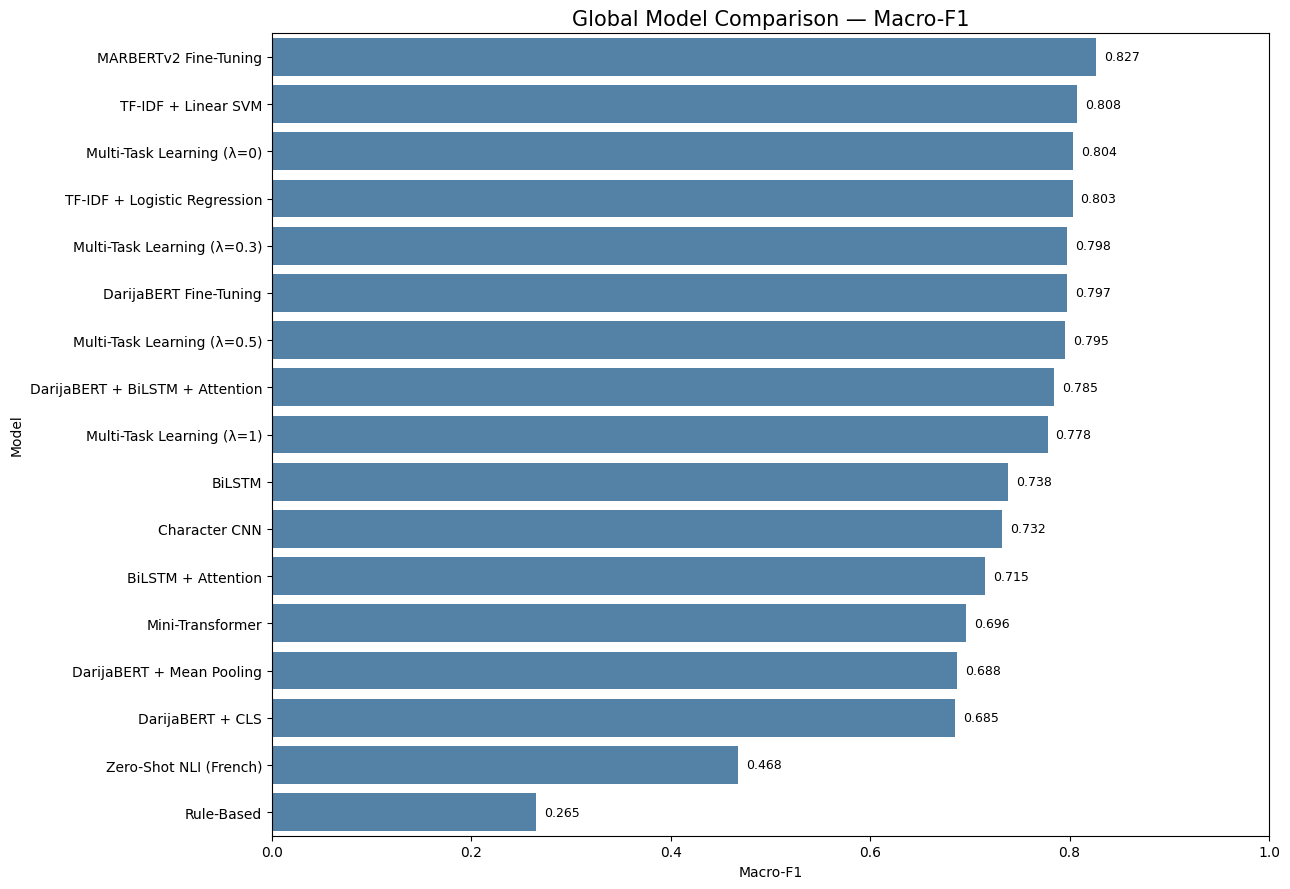

In [42]:

# ==========================================
# GLOBAL MODEL COMPARISON — VALIDATION
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Results from our experiments
results_global = pd.DataFrame([
    ["Rule-Based", 0.2650, 0.0000, None],
    ["TF-IDF + Logistic Regression", 0.8031, 0.7059, 0.7655],
    ["TF-IDF + Linear SVM", 0.8079, 0.6740, 0.7081],
    ["Zero-Shot NLI (French)", 0.4675, 0.3316, 0.2934],
    ["BiLSTM", 0.7380, 0.5936, 0.5847],
    ["BiLSTM + Attention", 0.7152, 0.5484, 0.5609],
    ["Mini-Transformer", 0.6962, 0.5182, 0.4704],
    ["Character CNN", 0.7324, 0.5852, 0.5798],
    ["DarijaBERT + CLS", 0.6850, 0.4979, 0.4489],
    ["DarijaBERT + Mean Pooling", 0.6875, 0.5145, 0.4811],
    ["DarijaBERT + BiLSTM + Attention", 0.7848, 0.6897, 0.7024],
    ["DarijaBERT Fine-Tuning", 0.7973, 0.6893, 0.7150],
    ["MARBERTv2 Fine-Tuning", 0.8265, 0.7283, 0.7818],
    ["Multi-Task Learning (λ=0)", 0.8036, 0.7075, 0.7323],
    ["Multi-Task Learning (λ=0.3)", 0.7978, 0.7097, 0.7234],
    ["Multi-Task Learning (λ=0.5)", 0.7951, 0.7085, 0.7217],
    ["Multi-Task Learning (λ=1)", 0.7780, 0.6757, 0.7018]
], columns=["Model", "Macro-F1", "Hate F1", "PR-AUC Hate"])

# Sort by Macro-F1
results_global = results_global.sort_values(
    "Macro-F1", ascending=False
).reset_index(drop=True)

print("GLOBAL MODEL COMPARISON — VALIDATION")
display(results_global.round(4))

# Visualization
plt.figure(figsize=(13, 9))

ax = sns.barplot(
    data=results_global,
    x="Macro-F1",
    y="Model",
    color="steelblue"
)

for bar in ax.patches:
    ax.text(
        bar.get_width() + 0.008,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.3f}",
        va="center",
        fontsize=9
    )

plt.title("Global Model Comparison — Macro-F1", fontsize=15)
plt.xlabel("Macro-F1")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

# Save results
results_global.to_csv(
    "/kaggle/working/global_comparison.csv",
    index=False
)


# Final Test Results Comparison

MOROCCAN DARIJA — TEST


,Experiment,Macro-F1,Hate F1
0,MARBERTv2 — Original,0.7668,0.6354
1,No Emojis,0.7703,0.6421
2,No Repeated Punctuation,0.7668,0.6354
3,No Insults,0.7599,0.6321
4,All Removed,0.7624,0.6387



ALGERIAN ARABIC — TEST


,Experiment,Macro-F1,Hate F1
0,Before Adaptation,0.6197,0.5083
1,After Adaptation,0.6632,0.5375


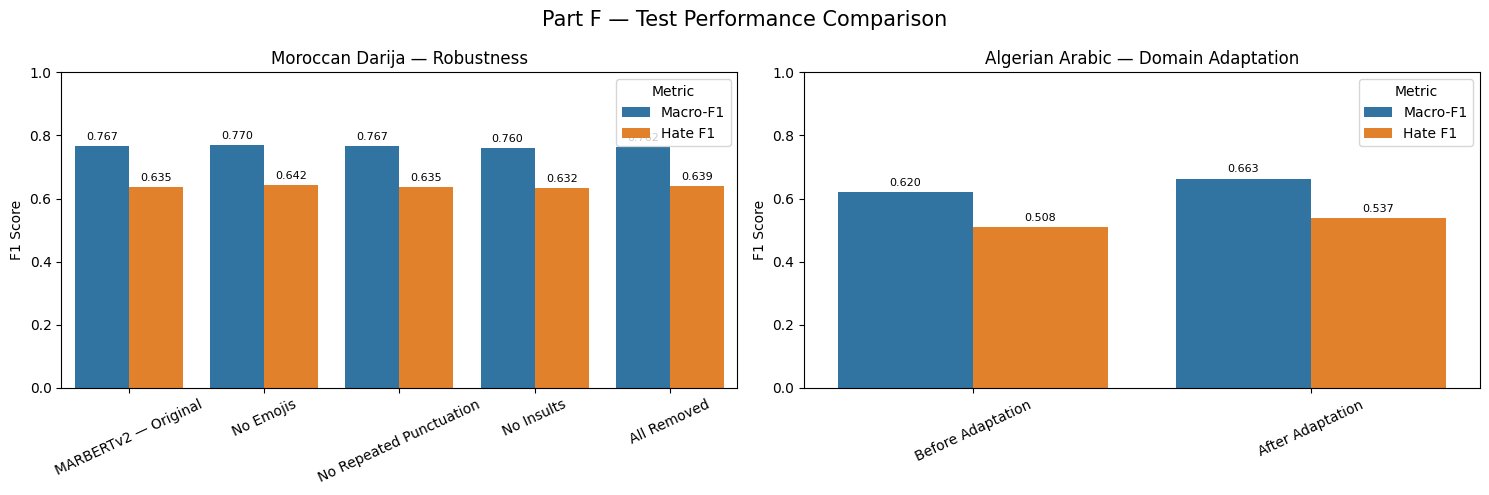

In [43]:

# =====================================================
# PART F — FINAL TEST RESULTS COMPARISON
# =====================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Moroccan Darija — Test Results
results_ary = pd.DataFrame([
    ["MARBERTv2 — Original", 0.7668, 0.6354],
    ["No Emojis", 0.7703, 0.6421],
    ["No Repeated Punctuation", 0.7668, 0.6354],
    ["No Insults", 0.7599, 0.6321],
    ["All Removed", 0.7624, 0.6387]
], columns=["Experiment", "Macro-F1", "Hate F1"])

# 2. Algerian Arabic — Test Results
results_arq = pd.DataFrame([
    ["Before Adaptation", 0.6197, 0.5083],
    ["After Adaptation", 0.6632, 0.5375]
], columns=["Experiment", "Macro-F1", "Hate F1"])

# 3. Display tables
print("MOROCCAN DARIJA — TEST")
display(results_ary)

print("\nALGERIAN ARABIC — TEST")
display(results_arq)

# 4. Comparison graphs
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, data, title in [
    (axes[0], results_ary, "Moroccan Darija — Robustness"),
    (axes[1], results_arq, "Algerian Arabic — Domain Adaptation")
]:
    plot_data = data.melt(
        id_vars="Experiment",
        value_vars=["Macro-F1", "Hate F1"],
        var_name="Metric",
        value_name="Score"
    )

    sns.barplot(
        data=plot_data,
        x="Experiment",
        y="Score",
        hue="Metric",
        ax=ax
    )

    ax.set_title(title)
    ax.set_ylim(0, 1)
    ax.set_xlabel("")
    ax.set_ylabel("F1 Score")
    ax.tick_params(axis="x", rotation=25)

    for container in ax.containers:
        ax.bar_label(
            container, fmt="%.3f",
            padding=3, fontsize=8
        )

plt.suptitle("Part F — Test Performance Comparison", fontsize=15)
plt.tight_layout()
plt.show()

# 5. Save
results_ary.to_csv(
    "/kaggle/working/F_comparison_ARY.csv",
    index=False
)

results_arq.to_csv(
    "/kaggle/working/F_comparison_ARQ.csv",
    index=False
)


# Final Model Comparison: Quality, Efficiency & Robustness

Linear SVM Size: 3.69 MB
MARBERTv2 Size: 621.22 MB

FINAL MODEL COMPARISON — TEST


,Model,Macro-F1,Hate F1,Latency (ms/tweet),Model Size (MB)
0,Linear SVM,0.7620,0.6082,0.2684,3.6917
1,MARBERTv2,0.7668,0.6354,7.8383,621.2217


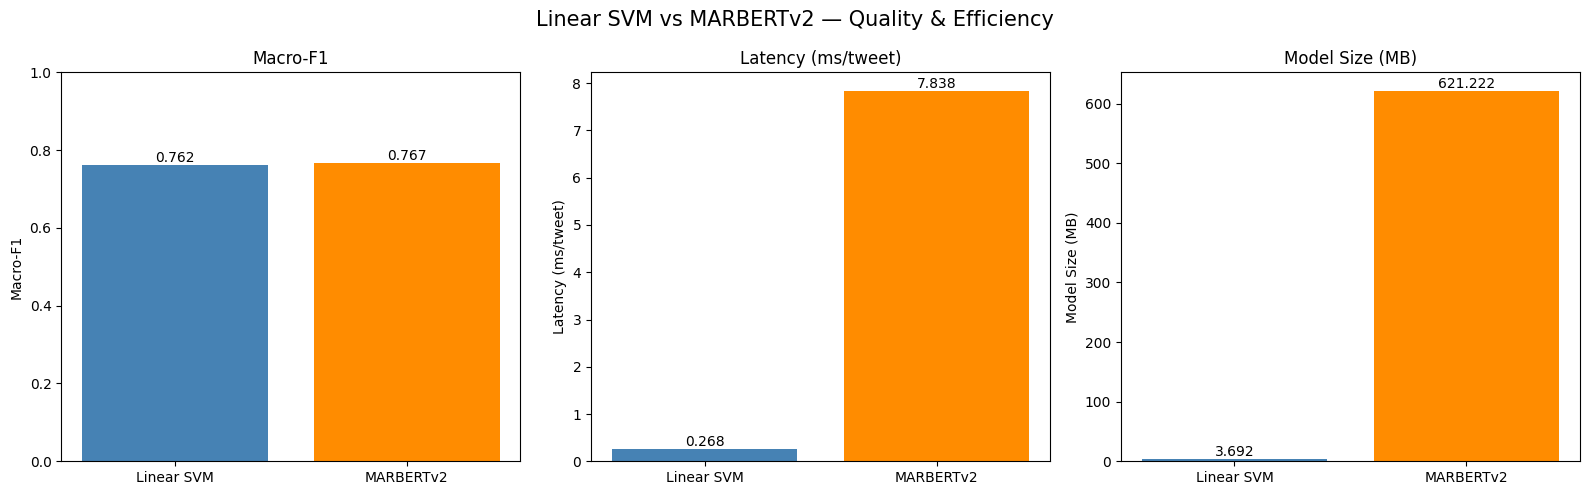


Comparison saved successfully!


In [56]:

# =====================================================
# PART G — FINAL MODEL COMPARISON
# Quality, Inference Latency & Model Size
# =====================================================

import os
import time
import numpy as np
import pandas as pd
import torch
import joblib
import matplotlib.pyplot as plt

from sklearn.metrics import f1_score

# =====================================================
# 1. CONFIGURATION
# =====================================================

CLASSES = ["Abuse", "Hate", "Normal"]

texts = df_test["tweet"].astype(str).tolist()
clean_texts = df_test["clean_tweet"].astype(str).tolist()
y_true = df_test["label"].to_numpy()

svm = trained_models_A["Linear SVM"]

marbert_path = "/kaggle/working/E1_MARBERTv2_seed42"

# =====================================================
# 2. LINEAR SVM — INFERENCE LATENCY
# =====================================================

# Warm-up
_ = svm.predict(clean_texts[:16])

start = time.perf_counter()

pred_svm = svm.predict(clean_texts)

svm_time = time.perf_counter() - start
svm_latency = (svm_time / len(texts)) * 1000

# =====================================================
# 3. MARBERTv2 — INFERENCE LATENCY
# =====================================================

# Warm-up GPU
_ = predict_probs_F(texts[:16])

if torch.cuda.is_available():
    torch.cuda.synchronize()

start = time.perf_counter()

marbert_probs = predict_probs_F(texts)

if torch.cuda.is_available():
    torch.cuda.synchronize()

marbert_time = time.perf_counter() - start
marbert_latency = (marbert_time / len(texts)) * 1000

# Predictions with validation-selected bias
pred_marbert = predict_with_bias(
    marbert_probs, best_bias
)

# =====================================================
# 4. MODEL SIZE
# =====================================================

# Linear SVM — complete pipeline
svm_path = "/kaggle/working/final_linear_svm.joblib"

joblib.dump(svm, svm_path)

svm_size = os.path.getsize(svm_path) / (1024 ** 2)

# MARBERTv2 — model weight files
marbert_size = sum(
    os.path.getsize(os.path.join(root, filename))
    for root, _, files in os.walk(marbert_path)
    for filename in files
    if filename.endswith((".safetensors", ".bin"))
) / (1024 ** 2)

print(f"Linear SVM Size: {svm_size:.2f} MB")
print(f"MARBERTv2 Size: {marbert_size:.2f} MB")

# =====================================================
# 5. FINAL COMPARISON
# =====================================================

results_G = pd.DataFrame([
    {
        "Model": "Linear SVM",
        "Macro-F1": f1_score(
            y_true, pred_svm,
            labels=CLASSES,
            average="macro"
        ),
        "Hate F1": f1_score(
            y_true == "Hate",
            pred_svm == "Hate"
        ),
        "Latency (ms/tweet)": svm_latency,
        "Model Size (MB)": svm_size
    },
    {
        "Model": "MARBERTv2",
        "Macro-F1": f1_score(
            y_true, pred_marbert,
            labels=CLASSES,
            average="macro"
        ),
        "Hate F1": f1_score(
            y_true == "Hate",
            pred_marbert == "Hate"
        ),
        "Latency (ms/tweet)": marbert_latency,
        "Model Size (MB)": marbert_size
    }
])

print("\nFINAL MODEL COMPARISON — TEST")
display(results_G.round(4))

# =====================================================
# 6. VISUALIZATION
# =====================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = [
    "Macro-F1",
    "Latency (ms/tweet)",
    "Model Size (MB)"
]

for ax, metric in zip(axes, metrics):

    bars = ax.bar(
        results_G["Model"],
        results_G[metric],
        color=["steelblue", "darkorange"]
    )

    ax.set_title(metric)
    ax.set_ylabel(metric)

    if metric == "Macro-F1":
        ax.set_ylim(0, 1)

    for bar in bars:
        value = bar.get_height()

        ax.annotate(
            f"{value:.3f}",
            (
                bar.get_x() + bar.get_width() / 2,
                value
            ),
            ha="center",
            va="bottom",
            fontsize=10
        )

plt.suptitle(
    "Linear SVM vs MARBERTv2 — Quality & Efficiency",
    fontsize=15
)

plt.tight_layout()
plt.show()

# =====================================================
# 7. SAVE RESULTS
# =====================================================

results_G.to_csv(
    "/kaggle/working/final_model_comparison.csv",
    index=False
)

print("\nComparison saved successfully!")
